In [1]:
from TableToDict import GetDFv2, GetDF, DisplayColumns
from HuRI import GetHuRI
#from ccsblib import  huri
from  Load_CCSB_Data import GetOrfMapping
import pandas as pd
import numpy as np

from matplotlib import pyplot as plt
import seaborn as sns

from PandasToMySQL import MakeSummaryTable

%matplotlib inline
%config InlineBackend.figure_format='retina'

pd.options.display.max_rows = 1000
pd.options.display.max_columns = 60

In [2]:
from glob import glob

In [3]:
from statsmodels.nonparametric.smoothers_lowess import lowess as  sm_lowess
from scipy.stats import pearsonr, spearmanr, linregress

## Load data

### qY2H hsPRS-RRSv2 

In [4]:
iscore_d = {}
plate_d = {1:('DBB_ADA_r1',1),
           2:('DBA_ADB_r1',1),
           3:('DBB_ADA_r1',2),
           4:('DBA_ADB_r1',2),
           5:('DBB_EAD_r1',1),
           6:('DBA_EAD_r1',1),
           7:('DBB_EAD_r1',2),
           8:('DBA_EAD_r1',2),
           87:('DBB_ADA_r2',1),
           88:('DBA_ADB_r2',1),
           89:('DBB_ADA_r2',2),
           90:('DBA_ADB_r2',2),
           91:('DBB_EAD_r2',1),
           92:('DBA_EAD_r2',1),
           93:('DBB_EAD_r2',2),
           94:('DBA_EAD_r2',2)
          }

for media in glob('../../../Raw_images_canon/20230227_nanoluc_y2h_hsPRSRRSv2/iScore/*'):
    media = media.split('/')[-1]
    
    if media not in iscore_d:
        iscore_d[media] = dict()

    for file_name in glob(f'../../../Raw_images_canon/20230227_nanoluc_y2h_hsPRSRRSv2/iScore/{media}/*.tsv'):
        plate = int(file_name.split('_')[-1][:-4])
        xp,pla_id = plate_d[plate]
        score_df = pd.read_csv(file_name, sep='\t', header=None)
        #score_d = dict(zip(score_df[0], score_df[1]))
        score_d = {(pla_id,well):score for well, score in zip(score_df[0],score_df[1])}
        if xp in iscore_d[media]:
            iscore_d[media][xp].update(score_d)
        else:
            iscore_d[media][xp] = score_d
             

### Previous pilot PRS-RRS xp

In [5]:
prs_rrs_pilot_res = {}
for file in glob('../hsPRSRRSv2_Choi_clones/data/20230206 hPRSRRSv2 pilot/*.xls'):

    df = pd.read_excel(file, skiprows=10, skipfooter=35, engine='xlrd')
    df.rename(columns={c:i+1 for i,c in enumerate(df.columns)}, inplace=True)
    pla = file.split('_')[-1][:-4]
    value_d = dict()
    for l, (i, row) in zip(['A','B','C','D','E','F','G','H'], df.iterrows()):
        for i, value in enumerate(row):
            key = (pla,f'{l}{str(i+1).zfill(2)}')
            prs_rrs_pilot_res[key] = value

*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'


### Current XP

In [6]:
res = {}
for file in glob('20230215_Full_scale_readout/*.xls'):

    df = pd.read_excel(file, skiprows=10, skipfooter=35, engine='xlrd')
    df.rename(columns={c:i+1 for i,c in enumerate(df.columns)}, inplace=True)
    
    if 'PRS' in file:
        pla = file.split('_')[-1][:-4]
        r = (int(file.split('_')[-3].split('/')[-1]) // 87)+1
        
        
        pla = f'{pla}_r{r}'
        
    else:
        if 'splashed' in file:
            pla = int(file.split('_')[-2])
            #print(file, pla)
        else:
            pla = int(file.split('_')[-1][:-4])
        
    #print(file, pla)
        
    value_d = dict()
    for l, (i, row) in zip(['A','B','C','D','E','F','G','H'], df.iterrows()):
        for i, value in enumerate(row):
            key = (pla,f'{l}{str(i+1).zfill(2)}')
            res[key] = value
            
            

*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: wi

In [7]:
empty_well_df = pd.read_excel('20230214_nY2H_post_diploid_selection.xlsx', header=None, skiprows=2)
empty_well_df.rename(columns={0:'plate_name', 1:'wells'}, inplace=True)
empty_well_df['plate_name'] = empty_well_df.plate_name.apply(lambda x: x.replace('AD2BxDB1A','AD2BxDB2A'))
empty_well_df['pla_id'] = empty_well_df.plate_name.apply(lambda x: int(x.split('_')[-1]) if 'NY2H' in x else np.nan)
empty_well_df['wells_set'] =  empty_well_df.wells.apply(lambda x: set(x.replace(' ','').split(',')))

empty_well_retest_d = {pla_id:wells_set for pla_id, wells_set in zip(empty_well_df.pla_id, empty_well_df.wells_set)}
#empty_well_df['plate_name'] = empty_well_df.apply(lambda x: x.replace('AD1AxDB1B','DB1A_ADB'))

empty_well_prsrrs_d = {f'{plate_name.split("_")[-1]}r{(int(plate_name.split(".")[0])//87)+1}':wells_set for plate_name, wells_set in zip(empty_well_df.plate_name, empty_well_df.wells_set) if 'PRS' in plate_name}

empty_well_df['prs_repeat'] = [f'r{(int(plate_name.split(".")[0])//87)+1}'  if 'PRS' in plate_name else np.nan for plate_name in empty_well_df.plate_name]
empty_well_df['prs_orient'] = empty_well_df.plate_name.apply(lambda x: x if 'PRS' not in x else 'DBA_ADB' if x[-1] == 'A' else 'DBB_ADA')
empty_well_df['empty_ctrl'] = empty_well_df.plate_name.apply(lambda x: 'empty' in x)
empty_well_df['prs_orient'] = [orient if not ectrl else  f'{orient[:3]}_EAD' for orient, ectrl in zip(empty_well_df.prs_orient,empty_well_df.empty_ctrl)]

empty_well_df['prs_pla_id'] = empty_well_df.plate_name.apply(lambda x: int(x[-2]) if 'PRS' in x else np.nan)

empty_well_df['prs_pla'] = empty_well_df.plate_name.apply(lambda x: 'PRS' in x)

empty_well_prsrrs_d = {(prs_repeat,prs_pla_id,prs_orient):wells_set for prs_repeat,prs_pla_id, prs_orient, wells_set in zip(empty_well_df.prs_repeat,empty_well_df.prs_pla_id,empty_well_df.prs_orient,empty_well_df.wells_set)}

empty_well_df.head()

,plate_name,wells,pla_id,wells_set,prs_repeat,prs_orient,empty_ctrl,prs_pla_id,prs_pla
0,1. hPRSRRSv2_AD1AxDB1B,"B01, C01, E01, H01, B02, A03, B04, G04, H04, C...",NaN,"{B12, E12, C01, G04, B02, B01, H01, H04, A12, ...",r1,DBB_ADA,False,1.0,True
1,2. hPRSRRSv2_AD1BxDB1A,"B01, C01, E01, B02, A03, B04, G04, H04, C05, D...",NaN,"{B12, E12, C01, G04, B02, B01, H04, A12, H08, ...",r1,DBA_ADB,False,1.0,True
2,3. hPRSRRSv2_AD2AxDB2B,"A01, B01, C01, G01, D02, G02, A03, H03, E04, H...",NaN,"{E12, C01, D09, D12, B08, B01, H04, F07, G02, ...",r1,DBB_ADA,False,2.0,True
3,4. hPRSRRSv2_AD2BxDB2A,"A01, B01, C01, G01, D02, G02, A03, H03, E04, H...",NaN,"{E12, C01, D09, D12, B08, B01, H04, F07, G02, ...",r1,DBA_ADB,False,2.0,True
4,5. hPRSRRSv2_emptyADxDB1B,"B01, C01, E01, H01, B02, A03, B04, G04, H04, C...",NaN,"{B12, E12, C01, G04, B02, B01, H01, H04, A12, ...",r1,DBB_EAD,True,1.0,True


## hs PRS RRS v2

In [8]:
prsrrsv2 = GetDF('prsrrsv2','prsrrsv2')
col = ['orf_ida', 'symbol_a','orf_idb', 'symbol_b','category', 'plate', 'well']
prsrrsv2 = prsrrsv2[prsrrsv2.is_v2==1][col].copy()

prsrrsv2['DBA_ADB_p'] = [prs_rrs_pilot_res['DB1AxAD1B',well] if pla == 1 else prs_rrs_pilot_res['DB2AxAD2B',well] for pla,well in zip(prsrrsv2.plate, prsrrsv2.well)]
prsrrsv2['DBA_EAD_p'] = [prs_rrs_pilot_res['DB1AxemptyAD',well] if pla == 1 else prs_rrs_pilot_res['DB2AxemptyAD',well] for pla,well in zip(prsrrsv2.plate, prsrrsv2.well)]
prsrrsv2['DBB_ADA_p'] = [prs_rrs_pilot_res['DB1BxAD1A',well] if pla == 1 else prs_rrs_pilot_res['DB2BxAD2A',well] for pla,well in zip(prsrrsv2.plate, prsrrsv2.well)]
prsrrsv2['DBB_EAD_p'] = [prs_rrs_pilot_res['DB1BxemptyAD',well] if pla == 1 else prs_rrs_pilot_res['DB2BxemptyAD',well] for pla,well in zip(prsrrsv2.plate, prsrrsv2.well)]

prsrrsv2['DBA_ADB_p_fail'] = [score < 5000 or ead_score < 5000 for score, ead_score in zip(prsrrsv2.DBA_ADB_p, prsrrsv2.DBA_EAD_p)]
prsrrsv2['DBB_ADA_p_fail'] = [score < 5000 or ead_score < 5000 for score, ead_score in zip(prsrrsv2.DBB_ADA_p, prsrrsv2.DBB_EAD_p)]

prsrrsv2['NLR_DBA_ADB_p'] = [np.log2(DBA_ADB/DBA_EAD) if not fail else np.nan for DBA_ADB,DBA_EAD, fail in zip(prsrrsv2.DBA_ADB_p, prsrrsv2.DBA_EAD_p, prsrrsv2.DBA_ADB_p_fail)]
prsrrsv2['NLR_DBB_ADA_p'] = [np.log2(DBB_ADA/DBB_EAD) if not fail else np.nan for DBB_ADA,DBB_EAD, fail in zip(prsrrsv2.DBB_ADA_p, prsrrsv2.DBB_EAD_p, prsrrsv2.DBB_ADA_p_fail)]

prsrrsv2['DBA_ADB_r1'] = [res['AD1BxDB1A_r1',well] if pla == 1 else res['AD2BxDB1A_r1',well] for pla,well in zip(prsrrsv2.plate, prsrrsv2.well)]
prsrrsv2['DBA_EAD_r1'] = [res['emptyADxDB1A_r1',well] if pla == 1 else res['emptyADxDB2A_r1',well] for pla,well in zip(prsrrsv2.plate, prsrrsv2.well)]
prsrrsv2['DBB_ADA_r1'] = [res['AD1AxDB1B_r1',well] if pla == 1 else res['AD2AxDB2B_r1',well] for pla,well in zip(prsrrsv2.plate, prsrrsv2.well)]
prsrrsv2['DBB_EAD_r1'] = [res['emptyADxDB1B_r1',well] if pla == 1 else res['emptyADxDB2B_r1',well] for pla,well in zip(prsrrsv2.plate, prsrrsv2.well)]

prsrrsv2['DBA_ADB_EW_r1'] = [well in empty_well_prsrrs_d['r1',pla,'DBA_ADB'] or  well in empty_well_prsrrs_d['r1',pla,'DBA_EAD'] for pla,well in zip(prsrrsv2.plate, prsrrsv2.well)]
prsrrsv2['DBB_ADA_EW_r1'] = [well in empty_well_prsrrs_d['r1',pla,'DBB_ADA'] or  well in empty_well_prsrrs_d['r1',pla,'DBB_EAD'] for pla,well in zip(prsrrsv2.plate, prsrrsv2.well)]
prsrrsv2['DBA_ADB_r1_fail'] = [score < 5000 or ead_score < 5000 for score, ead_score in zip(prsrrsv2.DBA_ADB_r1, prsrrsv2.DBA_EAD_r1)]
prsrrsv2['DBB_ADA_r1_fail'] = [score < 5000 or ead_score < 5000 for score, ead_score in zip(prsrrsv2.DBB_ADA_r1, prsrrsv2.DBB_EAD_r1)]

prsrrsv2['NLR_DBA_ADB_r1'] = [np.log2(DBA_ADB/DBA_EAD) if not fail else np.nan for DBA_ADB,DBA_EAD, fail in zip(prsrrsv2.DBA_ADB_r1, prsrrsv2.DBA_EAD_r1, prsrrsv2.DBA_ADB_r1_fail)]
prsrrsv2['NLR_DBB_ADA_r1'] = [np.log2(DBB_ADA/DBB_EAD) if not fail else np.nan for DBB_ADA,DBB_EAD, fail in zip(prsrrsv2.DBB_ADA_r1, prsrrsv2.DBB_EAD_r1, prsrrsv2.DBB_ADA_r1_fail)]

prsrrsv2['DBA_ADB_r2'] = [res['AD1BxDB1A_r2',well] if pla == 1 else res['AD2BxDB2A_r2',well] for pla,well in zip(prsrrsv2.plate, prsrrsv2.well)]
prsrrsv2['DBA_EAD_r2'] = [res['emptyADxDB1A_r2',well] if pla == 1 else res['emptyADxDB2A_r2',well] for pla,well in zip(prsrrsv2.plate, prsrrsv2.well)]
prsrrsv2['DBB_ADA_r2'] = [res['AD1AxDB1B_r2',well] if pla == 1 else res['AD2AxDB2B_r2',well] for pla,well in zip(prsrrsv2.plate, prsrrsv2.well)]
prsrrsv2['DBB_EAD_r2'] = [res['emptyADxDB1B_r2',well] if pla == 1 else res['emptyADxDB2B_r2',well] for pla,well in zip(prsrrsv2.plate, prsrrsv2.well)]

prsrrsv2['DBA_ADB_EW_r2'] = [well in empty_well_prsrrs_d['r2',pla,'DBA_ADB'] or  well in empty_well_prsrrs_d['r2',pla,'DBA_EAD'] for pla,well in zip(prsrrsv2.plate, prsrrsv2.well)]
prsrrsv2['DBB_ADA_EW_r2'] = [well in empty_well_prsrrs_d['r2',pla,'DBB_ADA'] or  well in empty_well_prsrrs_d['r2',pla,'DBB_EAD'] for pla,well in zip(prsrrsv2.plate, prsrrsv2.well)]
prsrrsv2['DBA_ADB_r2_fail'] = [score < 5000 or ead_score < 5000 for score, ead_score in zip(prsrrsv2.DBA_ADB_r2, prsrrsv2.DBA_EAD_r2)]
prsrrsv2['DBB_ADA_r2_fail'] = [score < 5000 or ead_score < 5000 for score, ead_score in zip(prsrrsv2.DBB_ADA_r2, prsrrsv2.DBB_EAD_r2)]

prsrrsv2['NLR_DBA_ADB_r2'] = [np.log2(DBA_ADB/DBA_EAD) if not fail else np.nan for DBA_ADB,DBA_EAD, fail in zip(prsrrsv2.DBA_ADB_r2, prsrrsv2.DBA_EAD_r2, prsrrsv2.DBA_ADB_r2_fail)]
prsrrsv2['NLR_DBB_ADA_r2'] = [np.log2(DBB_ADA/DBB_EAD) if not fail else np.nan for DBB_ADA,DBB_EAD, fail in zip(prsrrsv2.DBB_ADA_r2, prsrrsv2.DBB_EAD_r2, prsrrsv2.DBB_ADA_r2_fail)]

DBA_ADB_rrs_nlr_p = prsrrsv2[prsrrsv2.category == 'RRS'].NLR_DBA_ADB_p
DBB_ADA_rrs_nlr_p = prsrrsv2[prsrrsv2.category == 'RRS'].NLR_DBB_ADA_p

prsrrsv2['zNLR_DBA_ADB_p'] = prsrrsv2.NLR_DBA_ADB_p.apply(lambda x: (x-np.mean(DBA_ADB_rrs_nlr_p))/np.std(DBA_ADB_rrs_nlr_p))
prsrrsv2['zNLR_DBB_ADA_p'] = prsrrsv2.NLR_DBB_ADA_p.apply(lambda x: (x-np.mean(DBB_ADA_rrs_nlr_p))/np.std(DBB_ADA_rrs_nlr_p))

DBA_ADB_nlr_detection_p = (2.326 * np.std(DBA_ADB_rrs_nlr_p)) + np.mean(DBA_ADB_rrs_nlr_p)
DBB_ADA_nlr_detection_p = (2.326 * np.std(DBB_ADA_rrs_nlr_p)) + np.mean(DBB_ADA_rrs_nlr_p)

print(DBA_ADB_nlr_detection_p, DBB_ADA_nlr_detection_p)

prsrrsv2['dnY2H_DBA_ADB_p'] = prsrrsv2.NLR_DBA_ADB_p.apply(lambda x: 1 if x > DBA_ADB_nlr_detection_p else 0 if x == x else np.nan)
prsrrsv2['dnY2H_DBB_ADA_p'] = prsrrsv2.NLR_DBB_ADA_p.apply(lambda x: 1 if x > DBA_ADB_nlr_detection_p else 0 if x == x else np.nan)

DBA_ADB_rrs_nlr_r1 = prsrrsv2[prsrrsv2.category == 'RRS'].NLR_DBA_ADB_r1
DBB_ADA_rrs_nlr_r1 = prsrrsv2[prsrrsv2.category == 'RRS'].NLR_DBB_ADA_r1

prsrrsv2['zNLR_DBA_ADB_r1'] = prsrrsv2.NLR_DBA_ADB_r1.apply(lambda x: (x-np.mean(DBA_ADB_rrs_nlr_r1))/np.std(DBA_ADB_rrs_nlr_r1))
prsrrsv2['zNLR_DBB_ADA_r1'] = prsrrsv2.NLR_DBB_ADA_r1.apply(lambda x: (x-np.mean(DBB_ADA_rrs_nlr_r1))/np.std(DBB_ADA_rrs_nlr_r1))

DBA_ADB_nlr_detection_r1 = (2.326 * np.std(DBA_ADB_rrs_nlr_r1)) + np.mean(DBA_ADB_rrs_nlr_r1)
DBB_ADA_nlr_detection_r1 = (2.326 * np.std(DBB_ADA_rrs_nlr_r1)) + np.mean(DBB_ADA_rrs_nlr_r1)
print(DBA_ADB_nlr_detection_r1, DBB_ADA_nlr_detection_r1)

prsrrsv2['dnY2H_DBA_ADB_r1'] = prsrrsv2.NLR_DBA_ADB_r1.apply(lambda x: 1 if x > DBA_ADB_nlr_detection_r1 else 0 if x == x else np.nan)
prsrrsv2['dnY2H_DBB_ADA_r1'] = prsrrsv2.NLR_DBB_ADA_r1.apply(lambda x: 1 if x > DBA_ADB_nlr_detection_r1 else 0 if x == x else np.nan)

DBA_ADB_rrs_nlr_r2 = prsrrsv2[prsrrsv2.category == 'RRS'].NLR_DBA_ADB_r2
DBB_ADA_rrs_nlr_r2 = prsrrsv2[prsrrsv2.category == 'RRS'].NLR_DBB_ADA_r2

prsrrsv2['zNLR_DBA_ADB_r2'] = prsrrsv2.NLR_DBA_ADB_r2.apply(lambda x: (x-np.mean(DBA_ADB_rrs_nlr_r2))/np.std(DBA_ADB_rrs_nlr_r2))
prsrrsv2['zNLR_DBB_ADA_r2'] = prsrrsv2.NLR_DBB_ADA_r2.apply(lambda x: (x-np.mean(DBB_ADA_rrs_nlr_r2))/np.std(DBB_ADA_rrs_nlr_r2))

DBA_ADB_nlr_detection_r2 = (2.326 * np.std(DBA_ADB_rrs_nlr_r2)) + np.mean(DBA_ADB_rrs_nlr_r2)
DBB_ADA_nlr_detection_r2 = (2.326 * np.std(DBB_ADA_rrs_nlr_r2)) + np.mean(DBB_ADA_rrs_nlr_r2)
print(DBA_ADB_nlr_detection_r2, DBB_ADA_nlr_detection_r2)

prsrrsv2['dnY2H_DBA_ADB_r2'] = prsrrsv2.NLR_DBA_ADB_r2.apply(lambda x: 1 if x > DBA_ADB_nlr_detection_r2 else 0 if x == x else np.nan)
prsrrsv2['dnY2H_DBB_ADA_r2'] = prsrrsv2.NLR_DBB_ADA_r2.apply(lambda x: 1 if x > DBA_ADB_nlr_detection_r2 else 0 if x == x else np.nan)

thrshold_d = {'DBA_ADB_p':DBA_ADB_nlr_detection_p,
              'DBB_ADA_p':DBB_ADA_nlr_detection_p,
              'DBA_ADB_r1':DBA_ADB_nlr_detection_r1,
              'DBB_ADA_r1':DBB_ADA_nlr_detection_r1,
              'DBA_ADB_r2':DBA_ADB_nlr_detection_r2,
              'DBB_ADA_r2':DBB_ADA_nlr_detection_r2,
             }

for repeat, media in zip(['r01','r03','r04','r05'],['LW','LWH','LWH10','LWH25']):
    for orient in iscore_d[repeat]:
        prsrrsv2[f'{media}_{orient}'] = [iscore_d[repeat][orient][pla,well] for pla,well in zip(prsrrsv2.plate, prsrrsv2.well)]


def process_qy2h(lw,lwh1,lwh10,lwh25,lw_ctrl,lwh1_ctrl,lwh10_ctrl,lwh25_ctrl):
    '''
    NA if LW fail
    AA if ctrl pos same lvl
    '''
    res = np.nan
    if lw == lw and lw_ctrl == lw_ctrl:
        scores = [1 if s >= 2 else 0 for s in [lwh1,lwh10,lwh25]]
        scores_ctrl = [1 if s >= 2 else 0 for s in [lwh1_ctrl,lwh10_ctrl,lwh25_ctrl]]
        if sum(scores) == 0:
            res = 0
        elif sum(scores) <= sum(scores_ctrl):
            res = -1
        else:
            res = sum(scores) - sum(scores_ctrl)
        
    return res

for orient in ['DBB_ADA', 'DBA_ADB']:
    for repeat in ['r1','r2']:
        prsrrsv2[f'qY2H_{orient}_{repeat}'] = [process_qy2h(lw,lwh1,lwh10,lwh25,lw_ctrl,lwh1_ctrl,lwh10_ctrl,lwh25_ctrl) for lw,lwh1,lwh10,lwh25,lw_ctrl,lwh1_ctrl,lwh10_ctrl,lwh25_ctrl \
                                               in zip(prsrrsv2[f'LW_{orient}_{repeat}'],
                                                      prsrrsv2[f'LWH_{orient}_{repeat}'],
                                                      prsrrsv2[f'LWH10_{orient}_{repeat}'],
                                                      prsrrsv2[f'LWH25_{orient}_{repeat}'],
                                                      prsrrsv2[f'LW_{orient[:4]}EAD_{repeat}'],
                                                      prsrrsv2[f'LWH_{orient[:4]}EAD_{repeat}'],
                                                      prsrrsv2[f'LWH10_{orient[:4]}EAD_{repeat}'],
                                                      prsrrsv2[f'LWH25_{orient[:4]}EAD_{repeat}']
                                                     )]
        
prsrrsv2.drop(columns=['LW_DBB_ADA_r2',
       'LW_DBA_ADB_r2', 'LW_DBA_ADB_r1', 'LW_DBB_EAD_r1', 'LW_DBA_EAD_r1',
       'LW_DBB_ADA_r1', 'LW_DBB_EAD_r2', 'LW_DBA_EAD_r2', 'LWH_DBA_ADB_r1',
       'LWH_DBB_ADA_r1', 'LWH_DBB_EAD_r1', 'LWH_DBA_EAD_r1', 'LWH_DBB_ADA_r2',
       'LWH_DBA_ADB_r2', 'LWH_DBA_EAD_r2', 'LWH_DBB_EAD_r2',
       'LWH10_DBA_EAD_r2', 'LWH10_DBB_EAD_r2', 'LWH10_DBB_ADA_r2',
       'LWH10_DBA_ADB_r2', 'LWH10_DBA_EAD_r1', 'LWH10_DBB_ADA_r1',
       'LWH10_DBA_ADB_r1', 'LWH10_DBB_EAD_r1', 'LWH25_DBA_ADB_r2',
       'LWH25_DBB_EAD_r2', 'LWH25_DBB_ADA_r2', 'LWH25_DBA_EAD_r2',
       'LWH25_DBA_EAD_r1', 'LWH25_DBB_EAD_r1', 'LWH25_DBA_ADB_r1',
       'LWH25_DBB_ADA_r1'],inplace=True)


prsrrsv2.head()

2.018286531808936 1.7883275720731053
1.3687541769110136 1.0340369669844331
2.033081942948206 1.5055388118646942


,orf_ida,symbol_a,orf_idb,symbol_b,category,plate,well,DBA_ADB_p,DBA_EAD_p,DBB_ADA_p,DBB_EAD_p,DBA_ADB_p_fail,DBB_ADA_p_fail,NLR_DBA_ADB_p,NLR_DBB_ADA_p,DBA_ADB_r1,DBA_EAD_r1,DBB_ADA_r1,DBB_EAD_r1,DBA_ADB_EW_r1,DBB_ADA_EW_r1,DBA_ADB_r1_fail,DBB_ADA_r1_fail,NLR_DBA_ADB_r1,NLR_DBB_ADA_r1,DBA_ADB_r2,DBA_EAD_r2,DBB_ADA_r2,DBB_EAD_r2,DBA_ADB_EW_r2,DBB_ADA_EW_r2,DBA_ADB_r2_fail,DBB_ADA_r2_fail,NLR_DBA_ADB_r2,NLR_DBB_ADA_r2,zNLR_DBA_ADB_p,zNLR_DBB_ADA_p,dnY2H_DBA_ADB_p,dnY2H_DBB_ADA_p,zNLR_DBA_ADB_r1,zNLR_DBB_ADA_r1,dnY2H_DBA_ADB_r1,dnY2H_DBB_ADA_r1,zNLR_DBA_ADB_r2,zNLR_DBB_ADA_r2,dnY2H_DBA_ADB_r2,dnY2H_DBB_ADA_r2,qY2H_DBB_ADA_r1,qY2H_DBB_ADA_r2,qY2H_DBA_ADB_r1,qY2H_DBA_ADB_r2
0,1108,LCP2,5001,NCK1,PRS,1,A01,201648,154525,213255,195766,False,False,0.383999,0.123449,8433,11545,18949,18187,False,False,False,False,-0.453150,0.059214,242771,96335,270419,239955,False,False,False,False,1.333464,0.172433,0.077138,-0.434010,0.0,0.0,0.099107,1.007478,0.0,0.0,1.490260,-0.166367,0.0,0.0,0,0,0,0
1,617,SHMT2,4447,STAC3,RRS,1,D01,208868,221298,220,184874,False,True,-0.083399,NaN,20172,25854,4388,16889,False,False,False,True,-0.358033,NaN,188527,164639,116617,85754,False,False,False,False,0.195465,0.443502,-0.566025,NaN,0.0,NaN,0.215367,NaN,0.0,NaN,0.130844,0.340423,0.0,0.0,0,0,0,0
2,3535,EMD,5887,ARMC1,RRS,1,F01,176809,209620,202207,223298,False,False,-0.245585,-0.143137,9663,23751,25916,25160,False,False,False,False,-1.297445,0.042711,126709,89324,173908,172454,False,False,False,False,0.504399,0.012113,-0.789201,-0.875953,0.0,0.0,-0.932865,0.985156,0.0,0.0,0.499887,-0.466101,0.0,0.0,0,0,0,0
3,3174,PDHB,7186,ZC3HC1,RRS,1,G01,224657,122075,281304,137698,False,False,0.879956,1.030622,14113,17740,13324,22185,False,False,False,False,-0.329981,-0.735557,113774,137375,123273,180972,False,False,False,False,-0.271949,-0.553910,0.759600,1.069888,0.0,0.0,0.249655,-0.067511,0.0,0.0,-0.427513,-1.524333,0.0,0.0,0,0,0,0
4,273,FKBP3,5046,NQO2,RRS,1,A02,157736,189196,130420,150440,False,False,-0.262370,-0.206023,7685,18166,5116,10638,False,False,False,False,-1.241124,-1.056139,188320,114476,92283,102920,False,False,False,False,0.718141,-0.157387,-0.812298,-0.980204,0.0,0.0,-0.864024,-0.501122,0.0,0.0,0.755216,-0.782995,0.0,0.0,0,0,0,0


In [10]:
col = ['orf_ida', 'symbol_a', 'orf_idb', 'symbol_b', 'category', 'plate',
       'well', 'DBA_ADB_p', 'DBA_EAD_p', 'DBB_ADA_p', 'DBB_EAD_p',
       'DBA_ADB_r1', 'DBA_EAD_r1', 'DBB_ADA_r1', 'DBB_EAD_r1', 'DBA_ADB_EW_r1',
       'DBB_ADA_EW_r1','DBA_ADB_r2', 'DBA_EAD_r2', 'DBB_ADA_r2',
       'DBB_EAD_r2', 'DBA_ADB_EW_r2', 'DBB_ADA_EW_r2']

prsrrsv2[col].to_csv('hsPRSRRSv2_nY2H_raw_data.csv', index=None)

col = ['orf_ida', 'symbol_a', 'orf_idb', 'symbol_b', 'category', 'plate',
       'well', 'DBA_ADB_p', 'DBA_EAD_p', 'DBB_ADA_p', 'DBB_EAD_p',
       'DBA_ADB_r1', 'DBA_EAD_r1', 'DBB_ADA_r1', 'DBB_EAD_r1', 'DBA_ADB_EW_r1',
       'DBB_ADA_EW_r1','DBA_ADB_r2', 'DBA_EAD_r2', 'DBB_ADA_r2',
       'DBB_EAD_r2', 'DBA_ADB_EW_r2', 'DBB_ADA_EW_r2','dnY2H_DBA_ADB_r1','dnY2H_DBB_ADA_r1','dnY2H_DBA_ADB_r2','dnY2H_DBB_ADA_r2']

prsrrsv2[col].to_csv('hsPRSRRSv2_nY2H_raw_detected_data.csv', index=None)

prsrrsv2[col].head()

,orf_ida,symbol_a,orf_idb,symbol_b,category,plate,well,DBA_ADB_p,DBA_EAD_p,DBB_ADA_p,DBB_EAD_p,DBA_ADB_r1,DBA_EAD_r1,DBB_ADA_r1,DBB_EAD_r1,DBA_ADB_EW_r1,DBB_ADA_EW_r1,DBA_ADB_r2,DBA_EAD_r2,DBB_ADA_r2,DBB_EAD_r2,DBA_ADB_EW_r2,DBB_ADA_EW_r2,dnY2H_DBA_ADB_r1,dnY2H_DBB_ADA_r1,dnY2H_DBA_ADB_r2,dnY2H_DBB_ADA_r2
0,1108,LCP2,5001,NCK1,PRS,1,A01,201648,154525,213255,195766,8433,11545,18949,18187,False,False,242771,96335,270419,239955,False,False,0.0,0.0,0.0,0.0
1,617,SHMT2,4447,STAC3,RRS,1,D01,208868,221298,220,184874,20172,25854,4388,16889,False,False,188527,164639,116617,85754,False,False,0.0,NaN,0.0,0.0
2,3535,EMD,5887,ARMC1,RRS,1,F01,176809,209620,202207,223298,9663,23751,25916,25160,False,False,126709,89324,173908,172454,False,False,0.0,0.0,0.0,0.0
3,3174,PDHB,7186,ZC3HC1,RRS,1,G01,224657,122075,281304,137698,14113,17740,13324,22185,False,False,113774,137375,123273,180972,False,False,0.0,0.0,0.0,0.0
4,273,FKBP3,5046,NQO2,RRS,1,A02,157736,189196,130420,150440,7685,18166,5116,10638,False,False,188320,114476,92283,102920,False,False,0.0,0.0,0.0,0.0


In [9]:
col = ['orf_ida', 'symbol_a', 'orf_idb', 'symbol_b', 'category', 'plate',
       'well',  'NLR_DBA_ADB_p', 'NLR_DBB_ADA_p','NLR_DBA_ADB_r1',
       'NLR_DBB_ADA_r1', 'NLR_DBA_ADB_r2', 'NLR_DBB_ADA_r2', 'zNLR_DBA_ADB_p',
       'zNLR_DBB_ADA_p', 'dnY2H_DBA_ADB_p', 'dnY2H_DBB_ADA_p',
       'zNLR_DBA_ADB_r1', 'zNLR_DBB_ADA_r1', 'dnY2H_DBA_ADB_r1',
       'dnY2H_DBB_ADA_r1', 'zNLR_DBA_ADB_r2', 'zNLR_DBB_ADA_r2',
       'dnY2H_DBA_ADB_r2', 'dnY2H_DBB_ADA_r2', 'qY2H_DBB_ADA_r1',
       'qY2H_DBB_ADA_r2', 'qY2H_DBA_ADB_r1', 'qY2H_DBA_ADB_r2']

prsrrsv2[col].to_csv('hsPRSRRSv2_nY2H.csv')
prsrrsv2[col].to_csv('hsPRSRRSv2_nY2H_all_data.csv')

In [10]:
def dataframe_piling(df, shared_col, col_to_pile, single_col_label, hue=False):
    '''
    shared_col: columns to keep
    col_to_pile: columns that will be condensed in one column
    single_col_label: label of condensed column
    hue: keep track of category, if not False, label = argument provided (str)
    '''
    l = []
    for c in col_to_pile:
        sub_df = df[shared_col].copy()
        sub_df[single_col_label] = df[c]
        if hue:
            sub_df[hue] = c
        l.append(sub_df)
        
    res = pd.concat(l).reset_index(drop=True)
    return res

shared_col = ['orf_ida','symbol_a','orf_idb','symbol_b','category','plate','well']
col_to_pile = ['NLR_DBA_ADB_r1', 'NLR_DBA_ADB_r2', 'NLR_DBB_ADA_r1', 'NLR_DBB_ADA_r2']

rrs_df = dataframe_piling(prsrrsv2.query("category == 'RRS'"), shared_col, col_to_pile, 'NLR', hue='experiment')
rrs_df['zNLR'] = rrs_df.NLR.apply(lambda x: (x-rrs_df.NLR.mean()) / (np.std(rrs_df.NLR)))

rrs_all_thresholds_d = {i:i*np.std(rrs_df.NLR)+rrs_df.NLR.mean() for i in [1.96,2,2.326,3]}

rrs_df.head()

,orf_ida,symbol_a,orf_idb,symbol_b,category,plate,well,NLR,experiment,zNLR
0,617,SHMT2,4447,STAC3,RRS,1,D01,-0.358033,NLR_DBA_ADB_r1,-0.190858
1,3535,EMD,5887,ARMC1,RRS,1,F01,-1.297445,NLR_DBA_ADB_r1,-1.308542
2,3174,PDHB,7186,ZC3HC1,RRS,1,G01,-0.329981,NLR_DBA_ADB_r1,-0.157483
3,273,FKBP3,5046,NQO2,RRS,1,A02,-1.241124,NLR_DBA_ADB_r1,-1.241533
4,5114,RAB3B,8764,BOC,RRS,1,C02,-1.621756,NLR_DBA_ADB_r1,-1.694397


In [11]:
# #Are EAD controls consistent across plates?

# shared_col = ['orf_ida','symbol_a','orf_idb','symbol_b','category','plate','well']
# col_to_pile = ['DBA_EAD_r1', 'DBB_EAD_r1', 'DBA_EAD_r2', 'DBB_EAD_r2']

# prs_rrs_ead_control = dataframe_piling(prsrrsv2.query("category == 'RRS'"), shared_col, col_to_pile, 'EAD_RLU', hue='experiment')
# prs_rrs_ead_control['EAD_RLU_log10'] = prs_rrs_ead_control.EAD_RLU.apply(np.log10)

# plt.figure(figsize=(8,3))
# plt.title('Empty AD signal for PRS-RRS')
# sns.histplot(data=prs_rrs_ead_control, x='EAD_RLU_log10', hue='experiment')
# plt.show()

In [12]:
# #Are EAD controls consistent across plates?

# shared_col = ['orf_ida','symbol_a','orf_idb','symbol_b','category','plate','well']
# col_to_pile = ['DBA_ADB_r1', 'DBB_ADA_r1', 'DBA_ADB_r2', 'DBB_ADA_r2']

# prs_rrs_ead_control = dataframe_piling(prsrrsv2.query("category == 'RRS'"), shared_col, col_to_pile, 'RLU', hue='experiment')
# prs_rrs_ead_control['EAD_NLR_log10'] = prs_rrs_ead_control.EAD_NLR.apply(np.log10)

# plt.figure(figsize=(8,3))
# #plt.title('Empty AD signal for PRS-RRS')
# sns.histplot(data=prs_rrs_ead_control, x='EAD_NLR_log10', hue='experiment')
# plt.show()

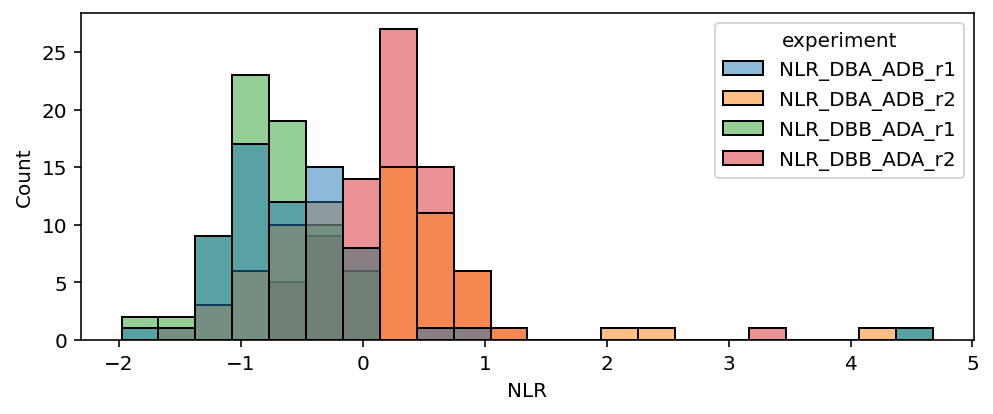

green 1.96 1.4497596440810316
lightblue 2 1.4833795834757928
salmon 2.326 1.7573820895430956
orange 3 2.3238780683448192


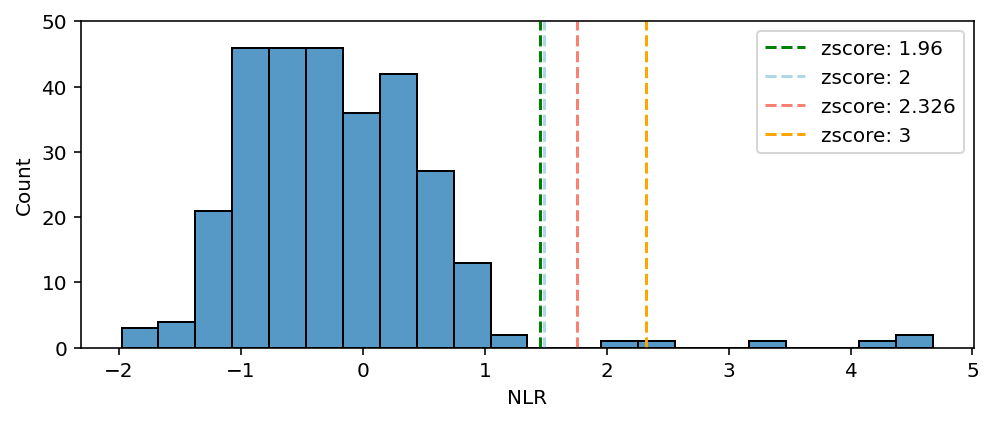

In [13]:
plt.figure(figsize=(8,3))
sns.histplot(data=rrs_df, x='NLR', hue='experiment')
plt.show()

plt.figure(figsize=(8,3))
sns.histplot(data=rrs_df, x='NLR')
for color,(zscore,threshold) in zip(['green','lightblue','salmon','orange'],rrs_all_thresholds_d.items()):
    print(color,zscore,threshold)
    plt.vlines(x=threshold, ymin=0, ymax=50, label=f'zscore: {zscore}', linestyles='--', color=color)
plt.ylim(0,50)
plt.legend()
plt.show()

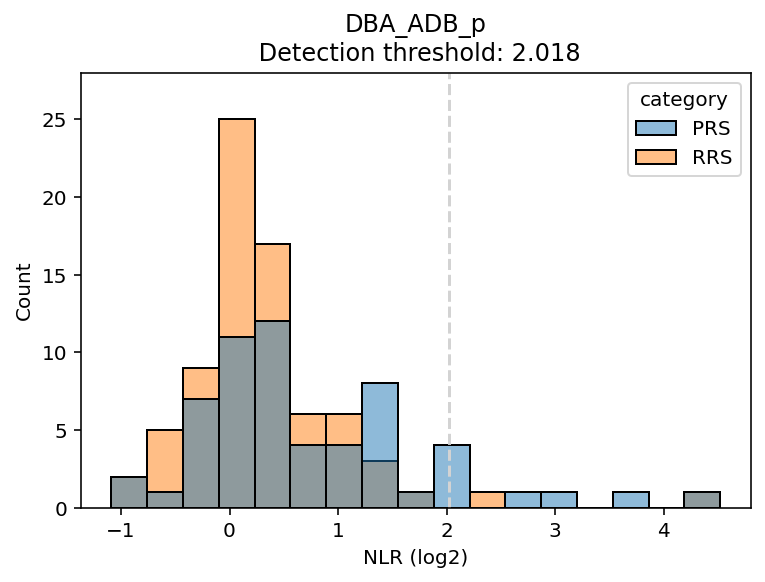

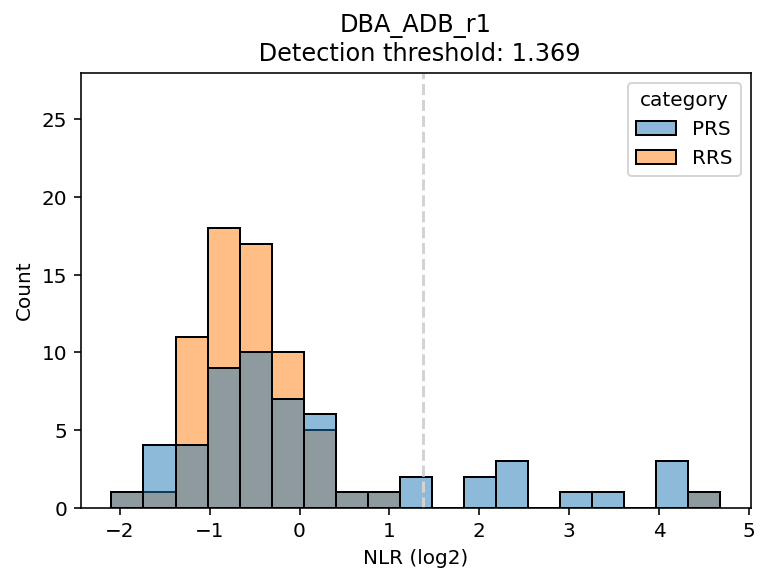

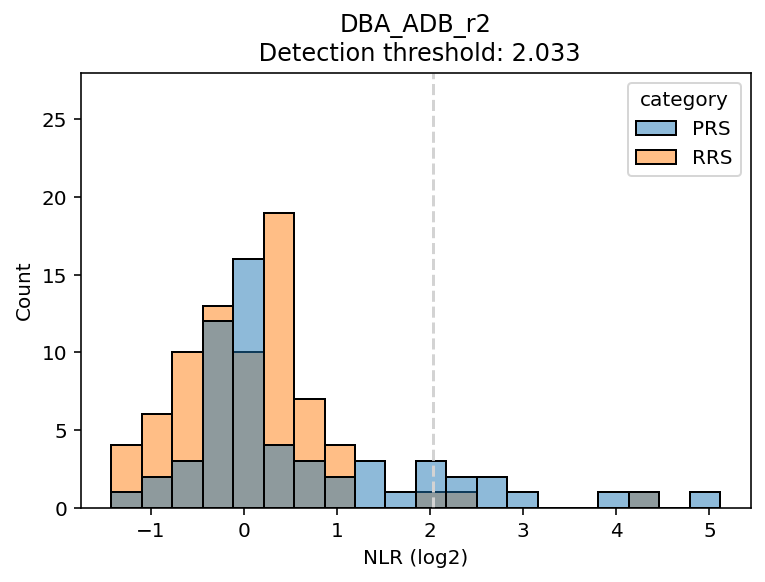

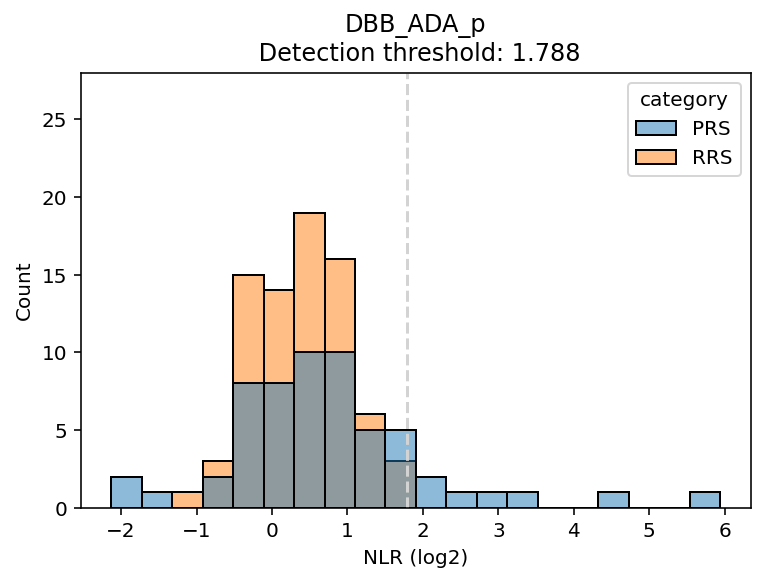

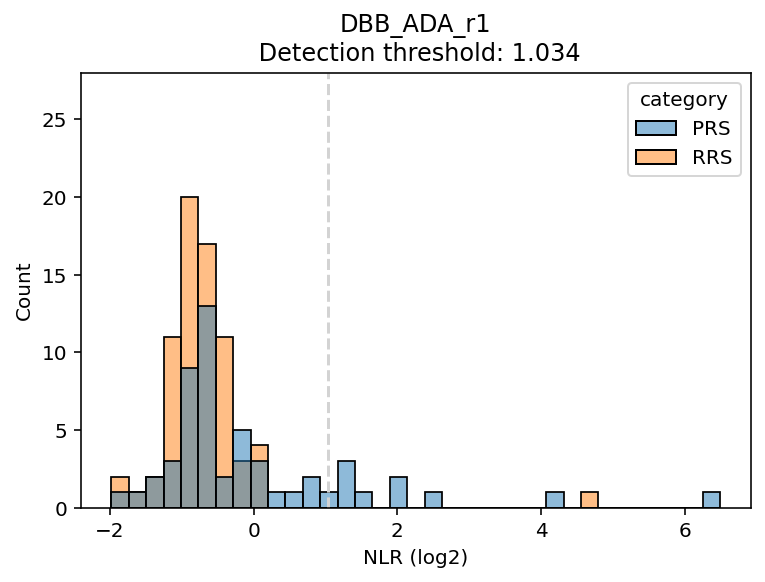

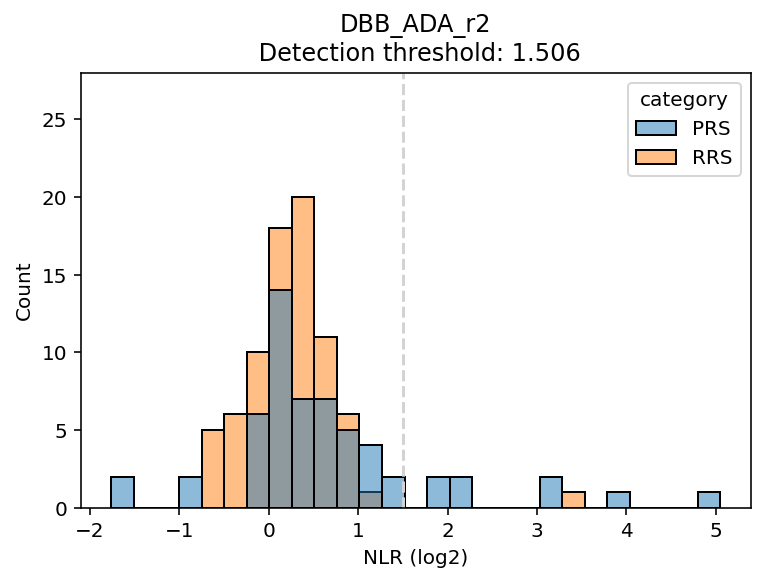

In [14]:
for orient in ['DBA_ADB','DBB_ADA']:
    for repeat in ['p','r1','r2']:
        plt.figure()
        threshold = thrshold_d[f'{orient}_{repeat}']
        plt.title(f"{orient}_{repeat}\n Detection threshold: {round(threshold,3)}")
        plt.vlines(ymin=0, ymax=28, x=thrshold_d[f'{orient}_{repeat}'], linestyles='--', color='lightgrey')
        plt.ylim(0,28)
        sns.histplot(data=prsrrsv2, x=f'NLR_{orient}_{repeat}', hue='category', legend=True)
        plt.xlabel('NLR (log2)')
        ;

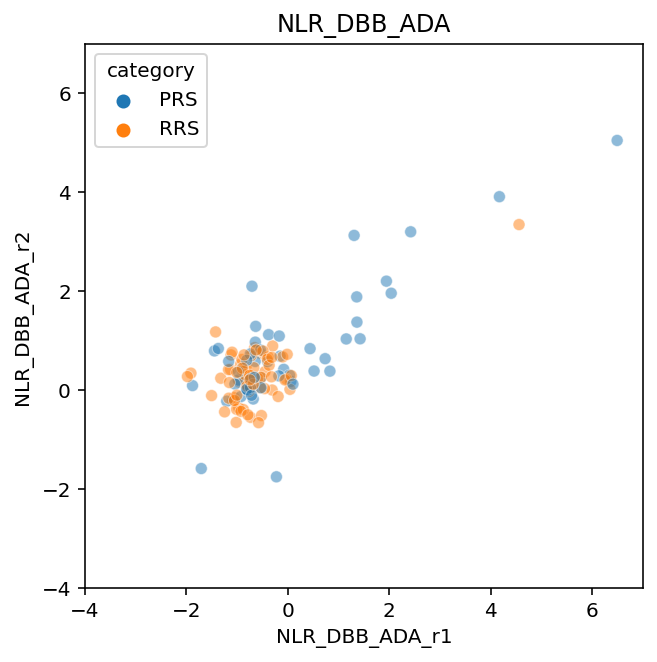

In [15]:
plt.figure(figsize=(5,5))
sns.scatterplot(data=prsrrsv2, x='NLR_DBB_ADA_r1', y='NLR_DBB_ADA_r2', hue='category', alpha=.5)

plt.xlim(-4,7)
plt.ylim(-4,7)
plt.title('NLR_DBB_ADA')
plt.show()


DBA_ADB DBA_ADB p r1


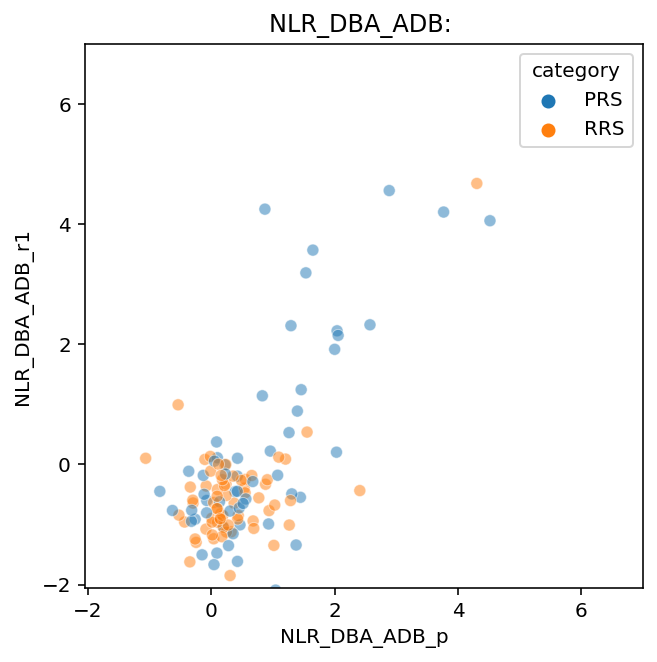

DBA_ADB DBA_ADB p r2


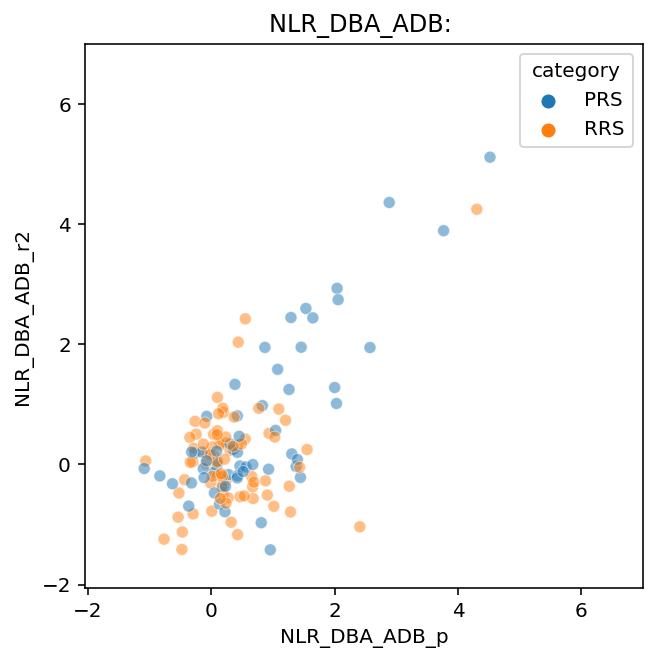

DBA_ADB DBA_ADB r1 r2


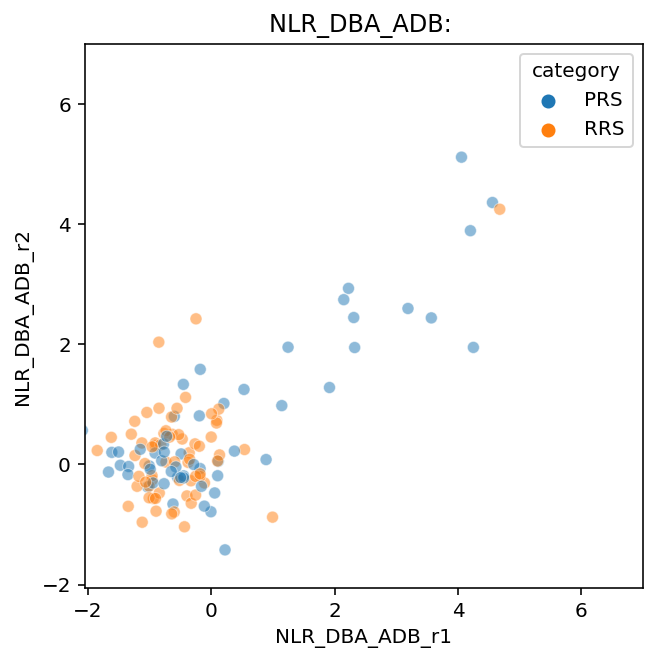

DBB_ADA DBB_ADA p r1


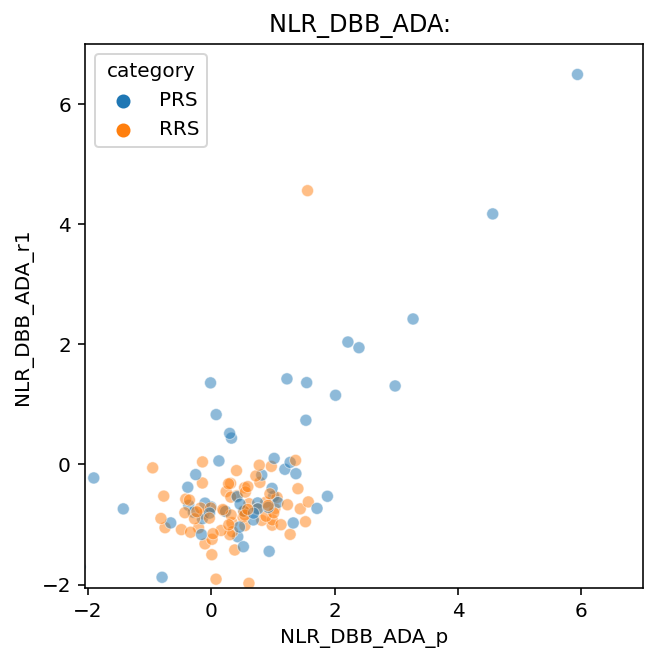

DBB_ADA DBB_ADA p r2


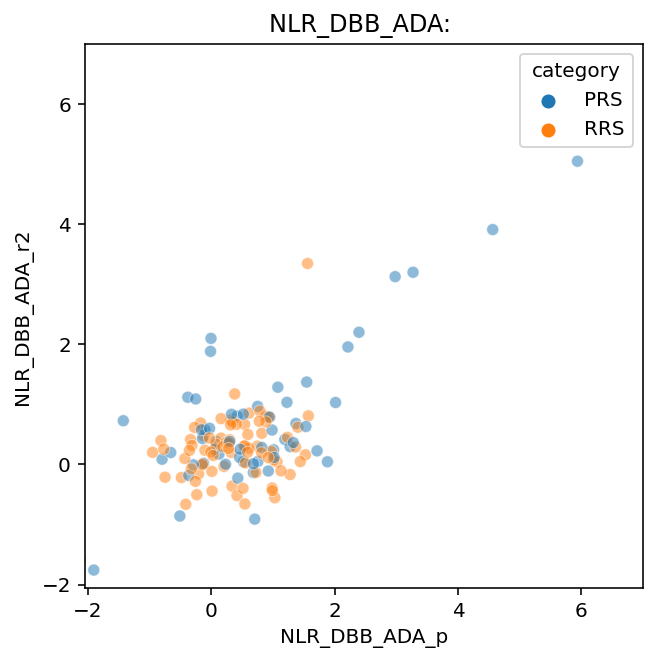

DBB_ADA DBB_ADA r1 r2


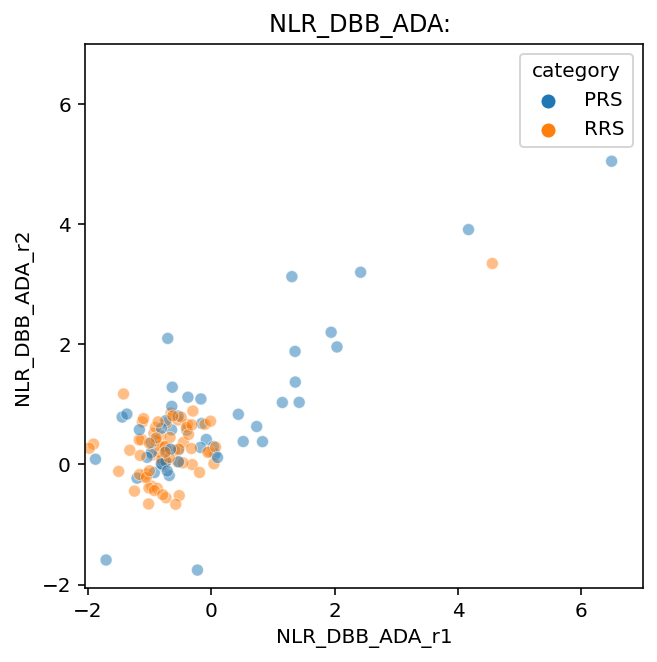

In [16]:
tested=set()
for orient1 in ['DBA_ADB','DBB_ADA']:
    for orient2 in ['DBA_ADB','DBB_ADA']:
        for repeat1 in ['p','r1','r2']:
            for repeat2 in ['p','r1','r2']:
                if orient1 == orient2 and repeat1 != repeat2 and (orient1,repeat1,repeat2) not in tested:
                    print(orient1,orient2,repeat1,repeat2)
                    tested.add((orient1,repeat2,repeat1))

                    plt.figure(figsize=(5,5))
                    sns.scatterplot(data=prsrrsv2, x=f'NLR_{orient1}_{repeat1}', y=f'NLR_{orient2}_{repeat2}', hue='category', alpha=.5)

                    plt.xlim(-2.05,7)
                    plt.ylim(-2.05,7)
                    plt.title(f'NLR_{orient1}: ')
                    plt.show()



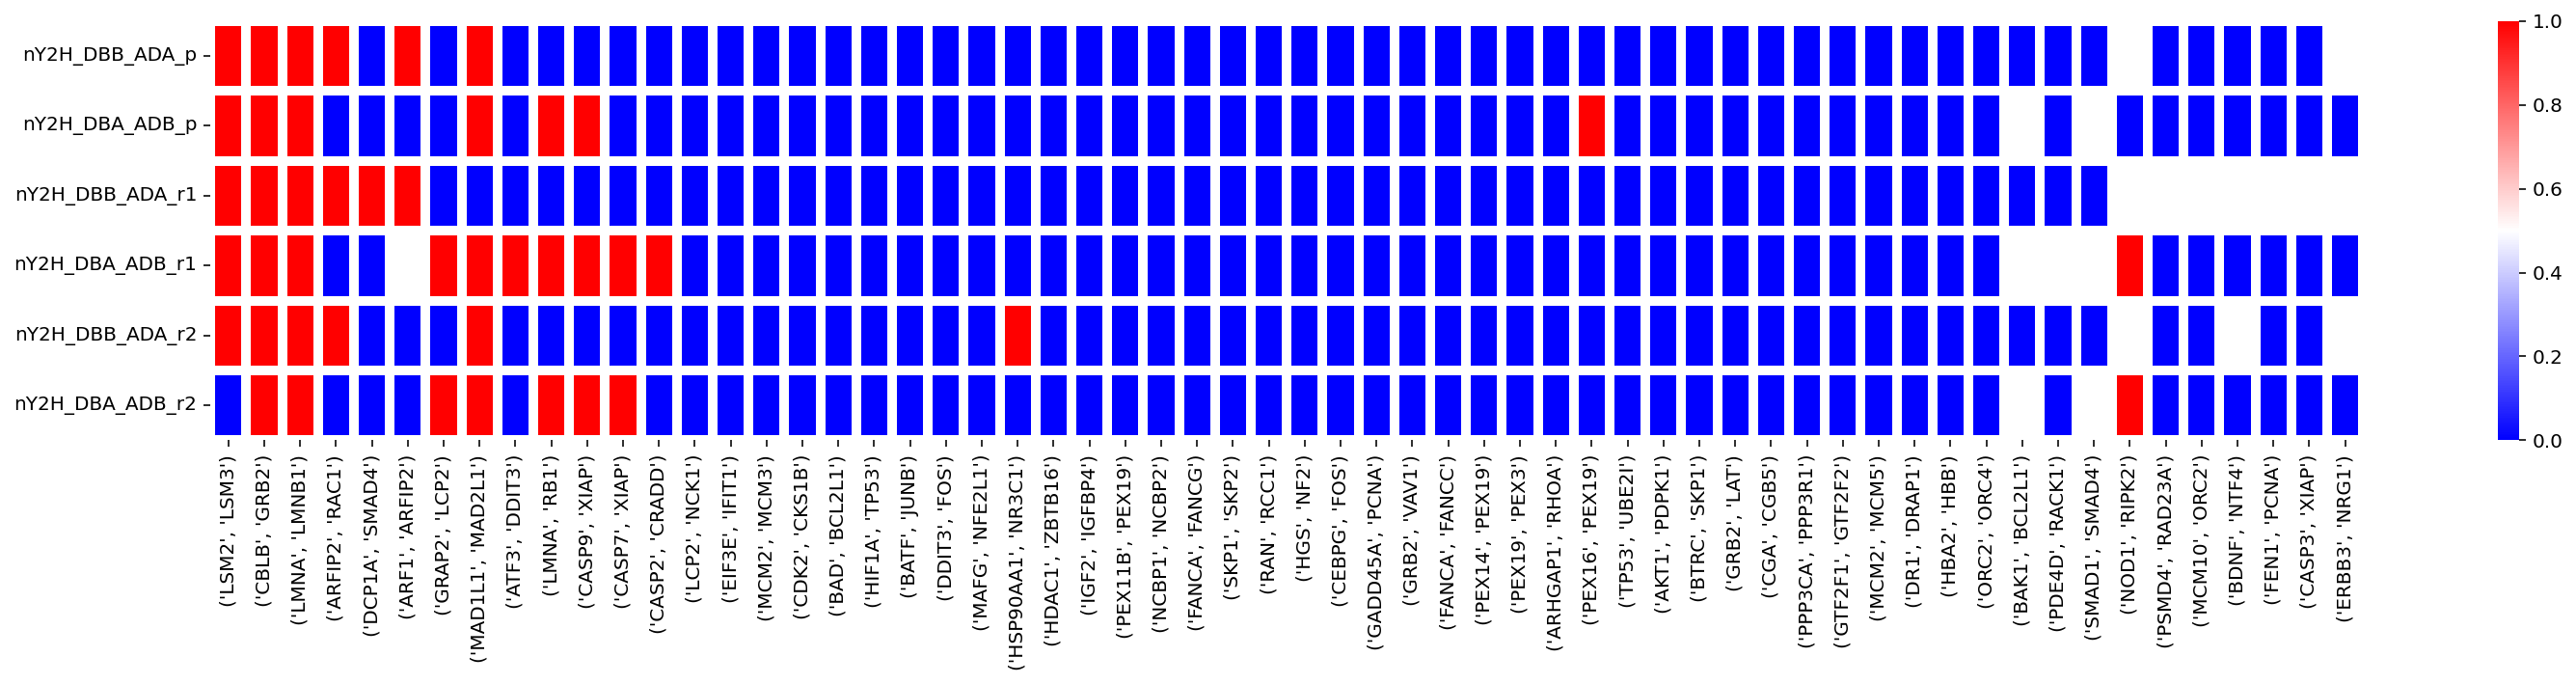

In [17]:
df = prsrrsv2[prsrrsv2.category == 'PRS'].copy()
df['pair']= [tuple(sorted([sa,sb])) for sa,sb in zip(df.symbol_a, df.symbol_b)]
col = ['pair','dnY2H_DBB_ADA_p', 'dnY2H_DBA_ADB_p','dnY2H_DBB_ADA_r1', 'dnY2H_DBA_ADB_r1','dnY2H_DBB_ADA_r2', 'dnY2H_DBA_ADB_r2']

df = df[col].copy()
df.set_index('pair', inplace=True)
df.rename(columns={c:c[1:] if c != 'pair' else 'pair' for c in df.columns},inplace=True)

df.sort_values(by=['nY2H_DBB_ADA_r1','nY2H_DBA_ADB_r1'], ascending=[False,False], inplace=True)

plt.figure(figsize=(25,4))
sns.heatmap(data=df.T, linewidth=5, cmap='bwr')
plt.xlabel('');
plt.show()

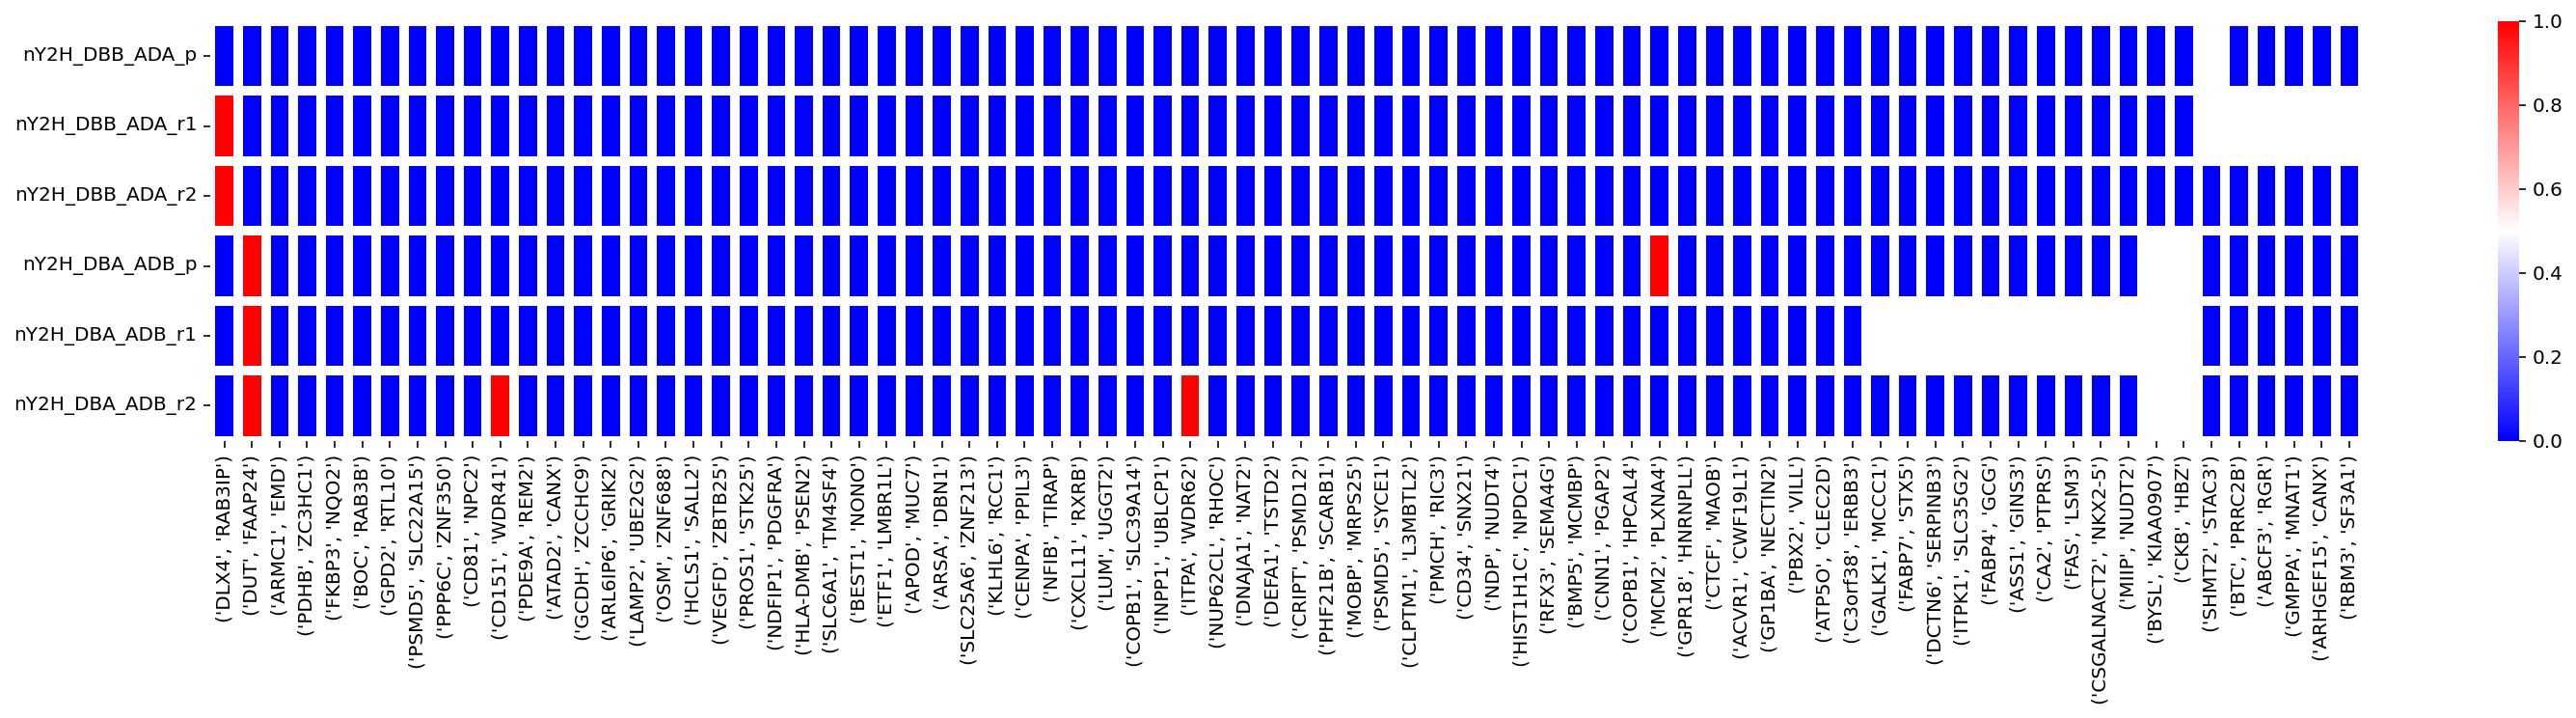

In [18]:
df = prsrrsv2[prsrrsv2.category == 'RRS'].copy()
df['pair']= [tuple(sorted([sa,sb])) for sa,sb in zip(df.symbol_a, df.symbol_b)]
col = ['pair','dnY2H_DBB_ADA_p','dnY2H_DBB_ADA_r1', 'dnY2H_DBB_ADA_r2','dnY2H_DBA_ADB_p', 'dnY2H_DBA_ADB_r1', 'dnY2H_DBA_ADB_r2']

df = df[col].copy()
df.set_index('pair', inplace=True)
df.rename(columns={c:c[1:] if c != 'pair' else 'pair' for c in df.columns},inplace=True)

df.sort_values(by=['nY2H_DBB_ADA_r1','nY2H_DBA_ADB_r1'], ascending=[False,False], inplace=True)

plt.figure(figsize=(25,4))
sns.heatmap(data=df.T, linewidth=5, cmap='bwr')
plt.xlabel('');
plt.show()

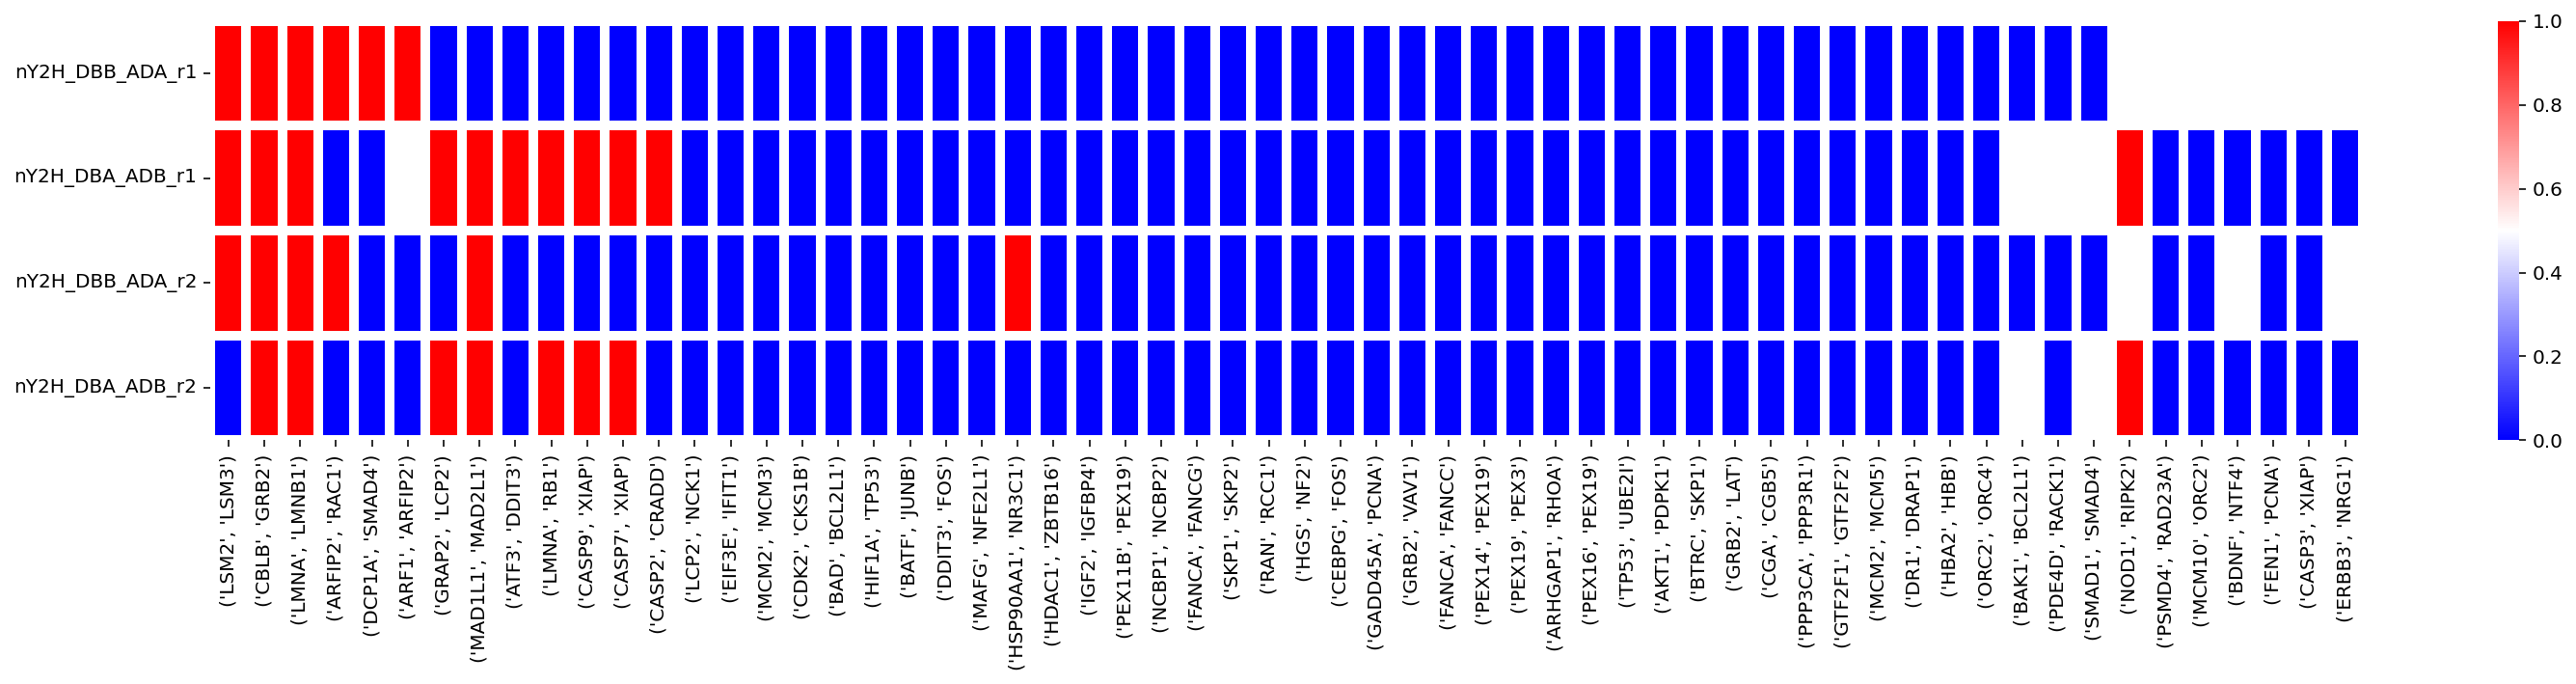

In [11]:
df = prsrrsv2[prsrrsv2.category == 'PRS'].copy()
df['pair']= [tuple(sorted([sa,sb])) for sa,sb in zip(df.symbol_a, df.symbol_b)]
col = ['pair','dnY2H_DBB_ADA_r1', 'dnY2H_DBA_ADB_r1','dnY2H_DBB_ADA_r2', 'dnY2H_DBA_ADB_r2']

df = df[col].copy()
df.set_index('pair', inplace=True)
df.rename(columns={c:c[1:] if c != 'pair' else 'pair' for c in df.columns},inplace=True)

df.sort_values(by=['nY2H_DBB_ADA_r1','nY2H_DBA_ADB_r1'], ascending=[False,False], inplace=True)

plt.figure(figsize=(25,4))
sns.heatmap(data=df.T, linewidth=5, cmap='bwr')
plt.xlabel('');
plt.show()

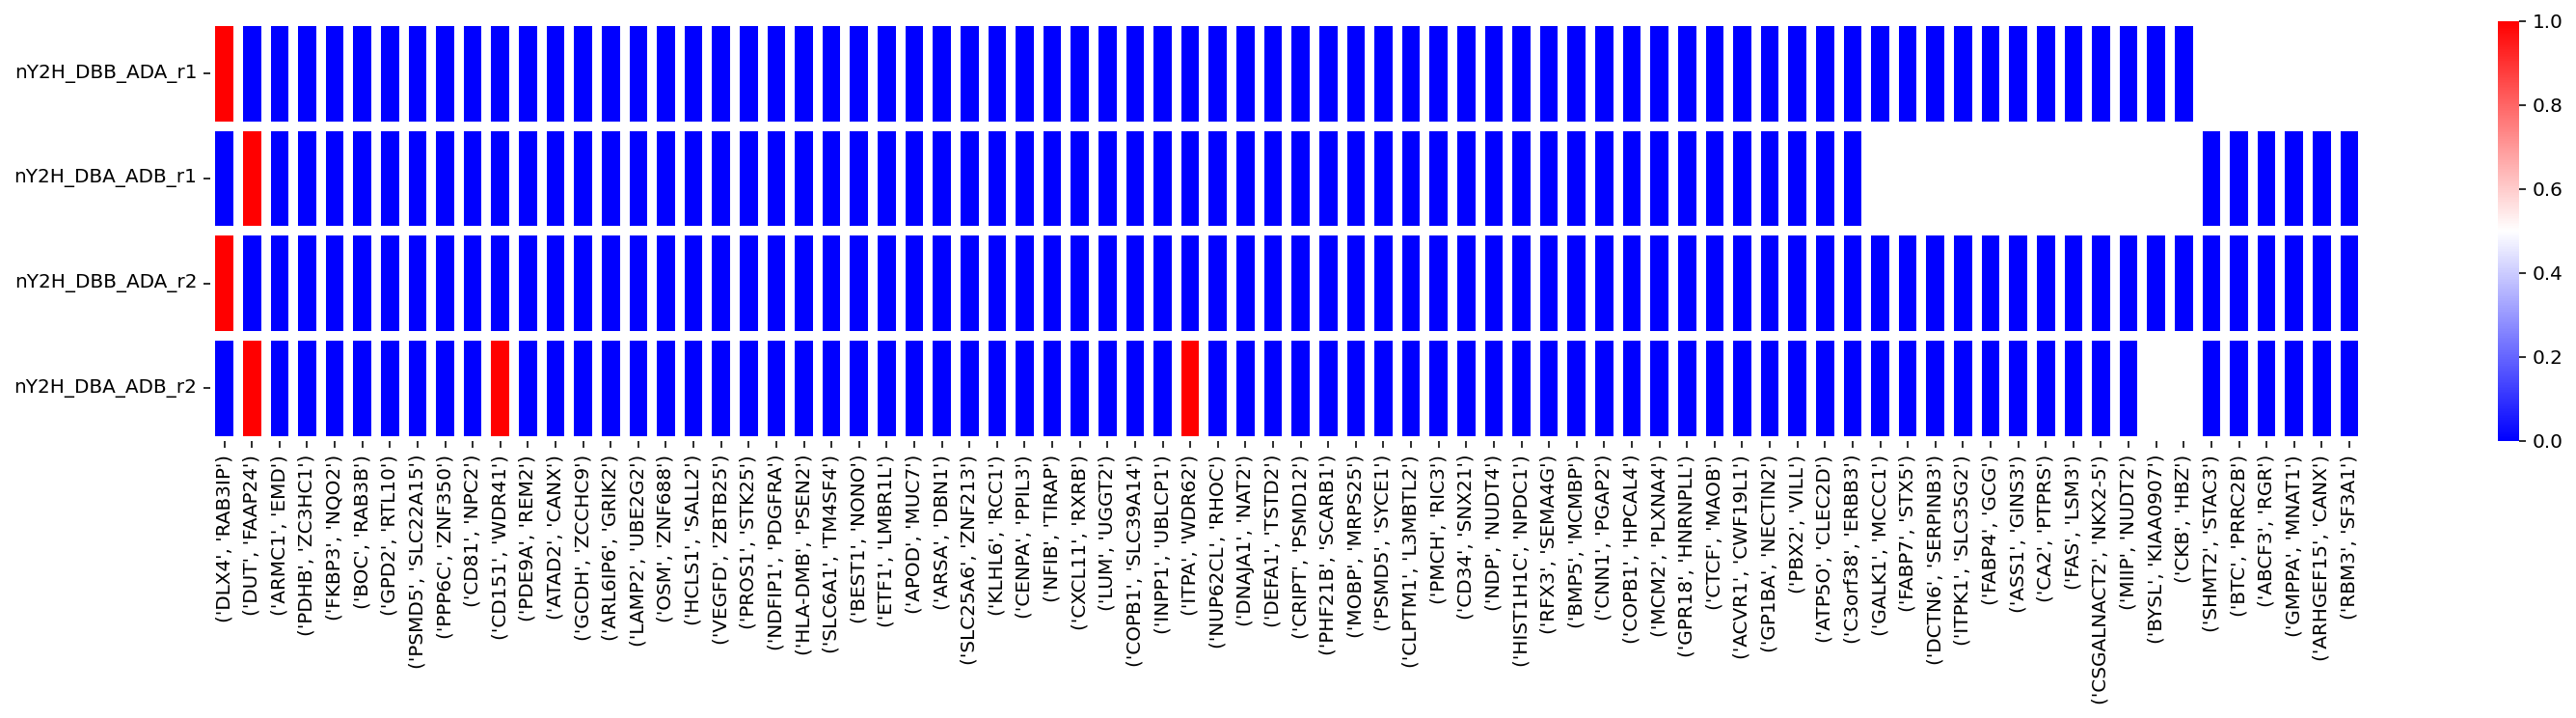

In [13]:
df = prsrrsv2[prsrrsv2.category == 'RRS'].copy()
df['pair']= [tuple(sorted([sa,sb])) for sa,sb in zip(df.symbol_a, df.symbol_b)]
col = ['pair','dnY2H_DBB_ADA_r1', 'dnY2H_DBA_ADB_r1', 'dnY2H_DBB_ADA_r2','dnY2H_DBA_ADB_r2']

df = df[col].copy()
df.set_index('pair', inplace=True)
df.rename(columns={c:c[1:] if c != 'pair' else 'pair' for c in df.columns},inplace=True)

df.sort_values(by=['nY2H_DBB_ADA_r1','nY2H_DBA_ADB_r1'], ascending=[False,False], inplace=True)

plt.figure(figsize=(25,4))
sns.heatmap(data=df.T, linewidth=5, cmap='bwr')
plt.xlabel('');
plt.show()

In [19]:
prsrrsv2.head()

,orf_ida,symbol_a,orf_idb,symbol_b,category,plate,well,DBA_ADB_p,DBA_EAD_p,DBB_ADA_p,DBB_EAD_p,DBA_ADB_p_fail,DBB_ADA_p_fail,NLR_DBA_ADB_p,NLR_DBB_ADA_p,DBA_ADB_r1,DBA_EAD_r1,DBB_ADA_r1,DBB_EAD_r1,DBA_ADB_EW_r1,DBB_ADA_EW_r1,DBA_ADB_r1_fail,DBB_ADA_r1_fail,NLR_DBA_ADB_r1,NLR_DBB_ADA_r1,DBA_ADB_r2,DBA_EAD_r2,DBB_ADA_r2,DBB_EAD_r2,DBA_ADB_EW_r2,DBB_ADA_EW_r2,DBA_ADB_r2_fail,DBB_ADA_r2_fail,NLR_DBA_ADB_r2,NLR_DBB_ADA_r2,zNLR_DBA_ADB_p,zNLR_DBB_ADA_p,dnY2H_DBA_ADB_p,dnY2H_DBB_ADA_p,zNLR_DBA_ADB_r1,zNLR_DBB_ADA_r1,dnY2H_DBA_ADB_r1,dnY2H_DBB_ADA_r1,zNLR_DBA_ADB_r2,zNLR_DBB_ADA_r2,dnY2H_DBA_ADB_r2,dnY2H_DBB_ADA_r2,qY2H_DBB_ADA_r1,qY2H_DBB_ADA_r2,qY2H_DBA_ADB_r1,qY2H_DBA_ADB_r2
0,1108,LCP2,5001,NCK1,PRS,1,A01,201648,154525,213255,195766,False,False,0.383999,0.123449,8433,11545,18949,18187,False,False,False,False,-0.453150,0.059214,242771,96335,270419,239955,False,False,False,False,1.333464,0.172433,0.077138,-0.434010,0.0,0.0,0.099107,1.007478,0.0,0.0,1.490260,-0.166367,0.0,0.0,0,0,0,0
1,617,SHMT2,4447,STAC3,RRS,1,D01,208868,221298,220,184874,False,True,-0.083399,NaN,20172,25854,4388,16889,False,False,False,True,-0.358033,NaN,188527,164639,116617,85754,False,False,False,False,0.195465,0.443502,-0.566025,NaN,0.0,NaN,0.215367,NaN,0.0,NaN,0.130844,0.340423,0.0,0.0,0,0,0,0
2,3535,EMD,5887,ARMC1,RRS,1,F01,176809,209620,202207,223298,False,False,-0.245585,-0.143137,9663,23751,25916,25160,False,False,False,False,-1.297445,0.042711,126709,89324,173908,172454,False,False,False,False,0.504399,0.012113,-0.789201,-0.875953,0.0,0.0,-0.932865,0.985156,0.0,0.0,0.499887,-0.466101,0.0,0.0,0,0,0,0
3,3174,PDHB,7186,ZC3HC1,RRS,1,G01,224657,122075,281304,137698,False,False,0.879956,1.030622,14113,17740,13324,22185,False,False,False,False,-0.329981,-0.735557,113774,137375,123273,180972,False,False,False,False,-0.271949,-0.553910,0.759600,1.069888,0.0,0.0,0.249655,-0.067511,0.0,0.0,-0.427513,-1.524333,0.0,0.0,0,0,0,0
4,273,FKBP3,5046,NQO2,RRS,1,A02,157736,189196,130420,150440,False,False,-0.262370,-0.206023,7685,18166,5116,10638,False,False,False,False,-1.241124,-1.056139,188320,114476,92283,102920,False,False,False,False,0.718141,-0.157387,-0.812298,-0.980204,0.0,0.0,-0.864024,-0.501122,0.0,0.0,0.755216,-0.782995,0.0,0.0,0,0,0,0


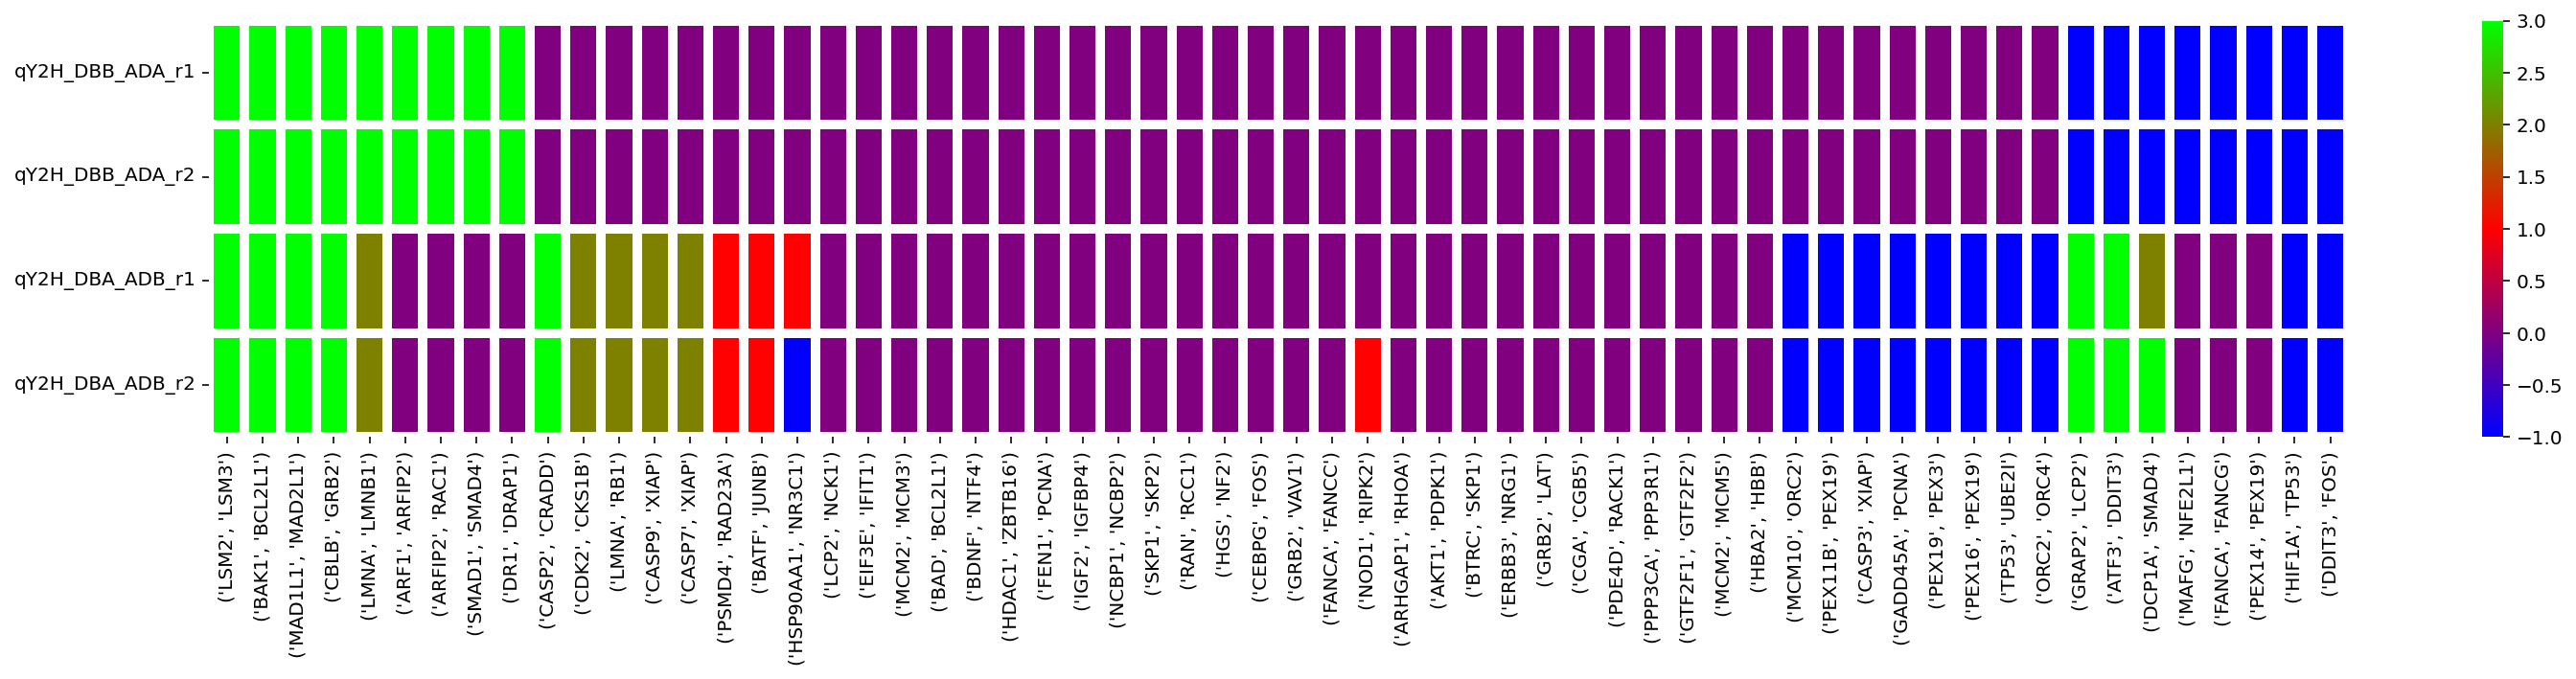

In [20]:
df = prsrrsv2[prsrrsv2.category == 'PRS'].copy()
df['pair']= [tuple(sorted([sa,sb])) for sa,sb in zip(df.symbol_a, df.symbol_b)]

col = ['pair','qY2H_DBB_ADA_r1','qY2H_DBB_ADA_r2','qY2H_DBA_ADB_r1','qY2H_DBA_ADB_r2']

df = df[col].copy()
df.set_index('pair', inplace=True)
#df.rename(columns={c:c[1:] if c != 'pair' else 'pair' for c in df.columns},inplace=True)

df.sort_values(by=['qY2H_DBB_ADA_r1','qY2H_DBA_ADB_r1'], ascending=[False,False], inplace=True)

plt.figure(figsize=(25,4))
sns.heatmap(data=df.T, linewidth=5, cmap='brg')
plt.xlabel('');
plt.show()

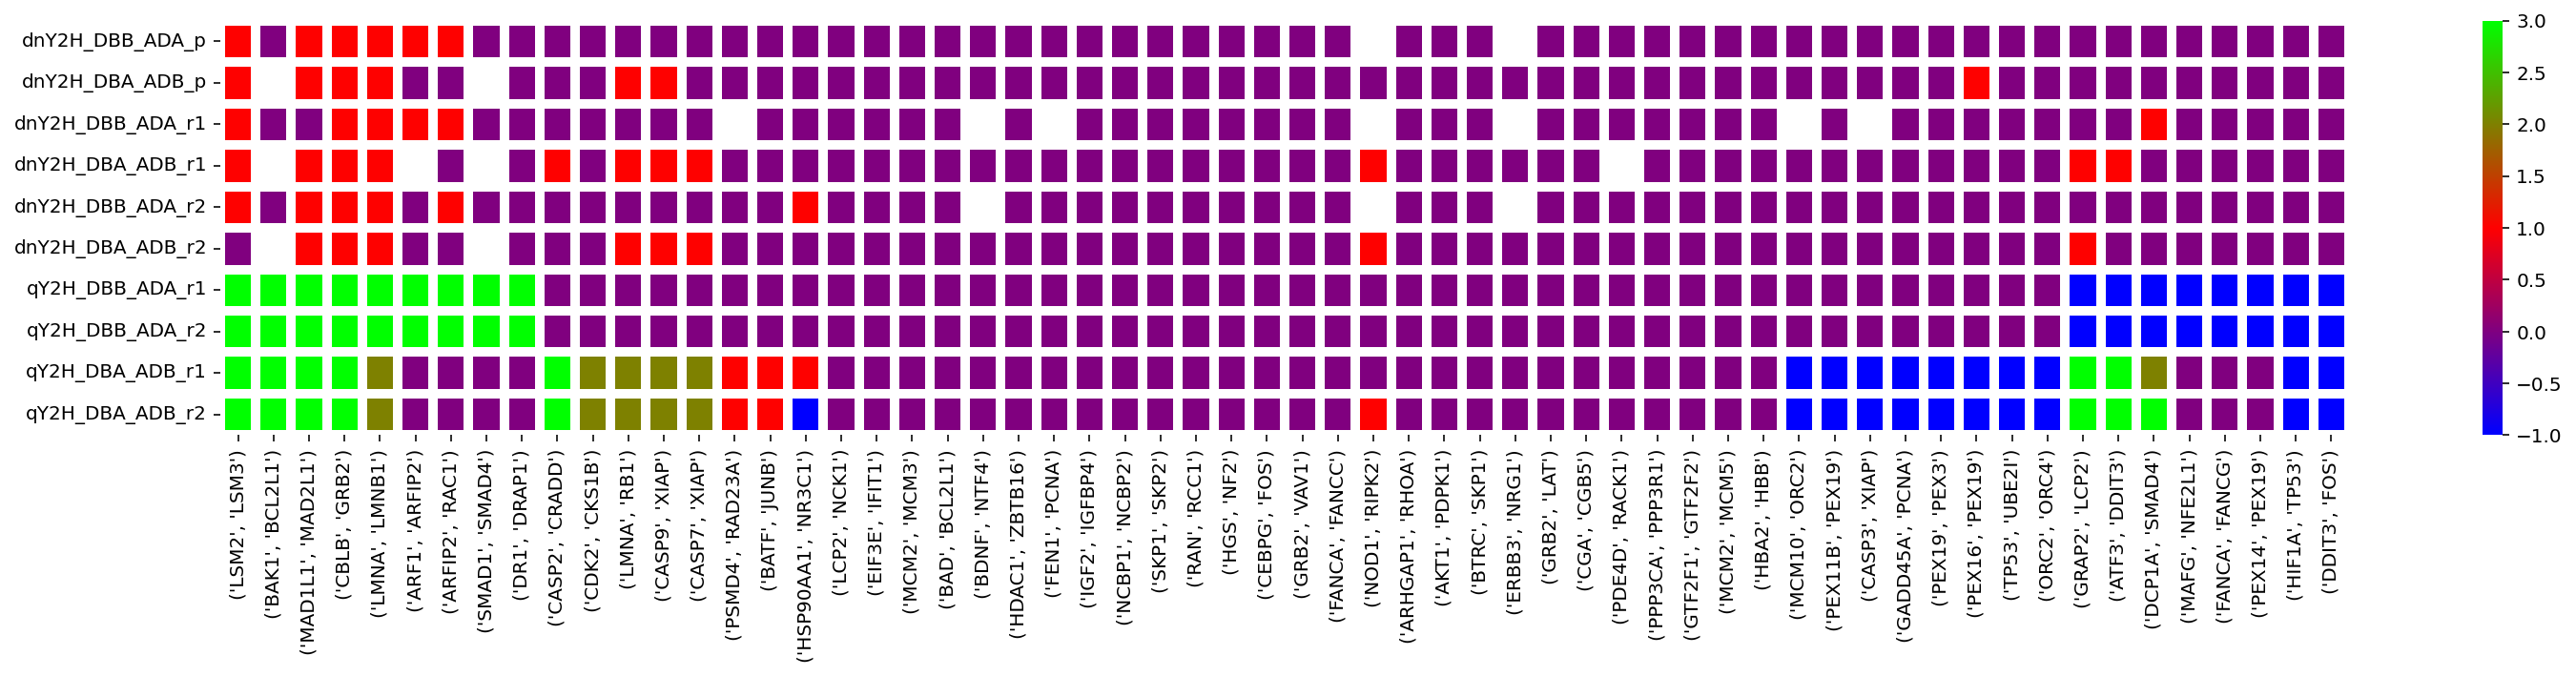

In [21]:
df = prsrrsv2[prsrrsv2.category == 'PRS'].copy()
df['pair']= [tuple(sorted([sa,sb])) for sa,sb in zip(df.symbol_a, df.symbol_b)]

col = ['pair','dnY2H_DBB_ADA_p', 'dnY2H_DBA_ADB_p','dnY2H_DBB_ADA_r1', 'dnY2H_DBA_ADB_r1','dnY2H_DBB_ADA_r2', 'dnY2H_DBA_ADB_r2','qY2H_DBB_ADA_r1','qY2H_DBB_ADA_r2','qY2H_DBA_ADB_r1','qY2H_DBA_ADB_r2']

df = df[col].copy()
df.set_index('pair', inplace=True)
#df.rename(columns={c:c[1:] if c != 'pair' else 'pair' for c in df.columns},inplace=True)

df.sort_values(by=['qY2H_DBB_ADA_r1','qY2H_DBA_ADB_r1'], ascending=[False,False], inplace=True)

plt.figure(figsize=(25,4))
sns.heatmap(data=df.T, linewidth=5, cmap='brg')
plt.xlabel('');
plt.show()

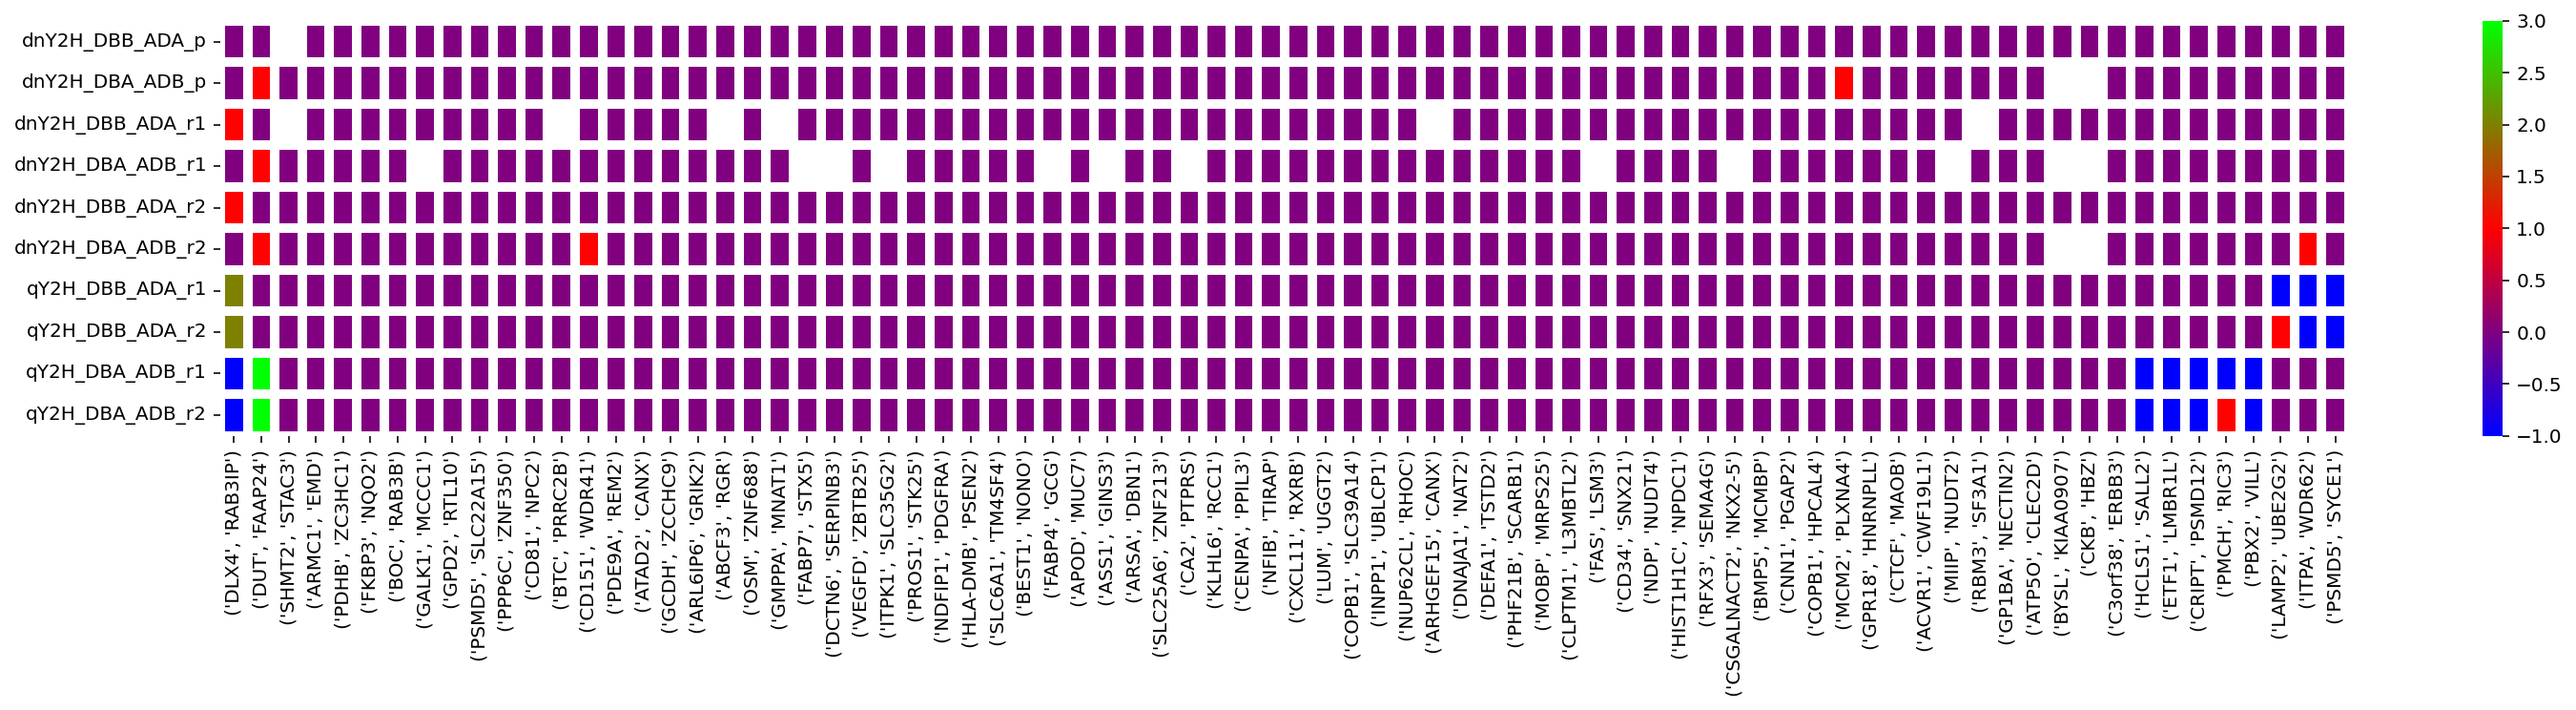

In [22]:
df = prsrrsv2[prsrrsv2.category == 'RRS'].copy()
df['pair']= [tuple(sorted([sa,sb])) for sa,sb in zip(df.symbol_a, df.symbol_b)]

col = ['pair','dnY2H_DBB_ADA_p', 'dnY2H_DBA_ADB_p','dnY2H_DBB_ADA_r1', 'dnY2H_DBA_ADB_r1','dnY2H_DBB_ADA_r2', 'dnY2H_DBA_ADB_r2','qY2H_DBB_ADA_r1','qY2H_DBB_ADA_r2','qY2H_DBA_ADB_r1','qY2H_DBA_ADB_r2']

df = df[col].copy()
df.set_index('pair', inplace=True)
#df.rename(columns={c:c[1:] if c != 'pair' else 'pair' for c in df.columns},inplace=True)

df.sort_values(by=['qY2H_DBB_ADA_r1','qY2H_DBA_ADB_r1'], ascending=[False,False], inplace=True)

plt.figure(figsize=(25,4))
sns.heatmap(data=df.T, linewidth=5, cmap='brg')
plt.xlabel('');
plt.show()

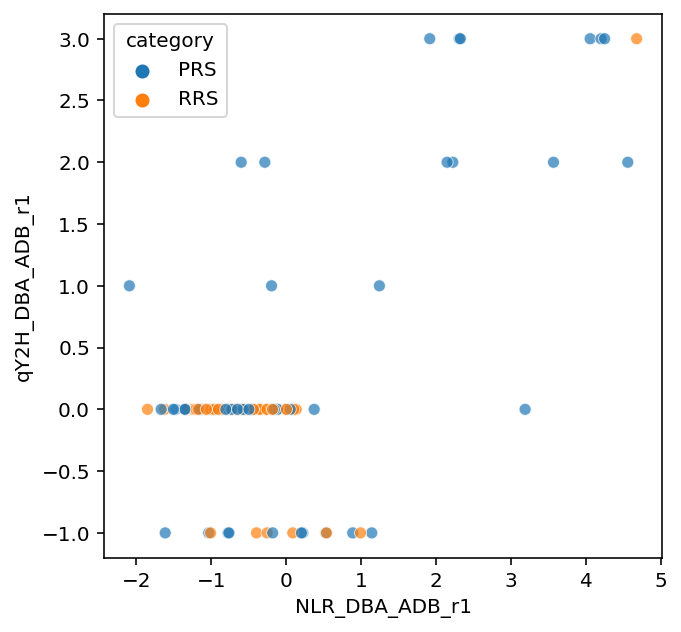

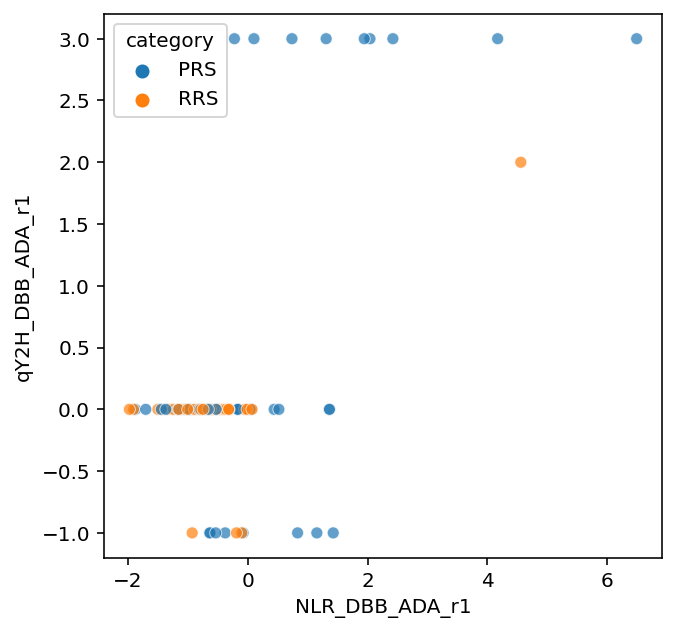

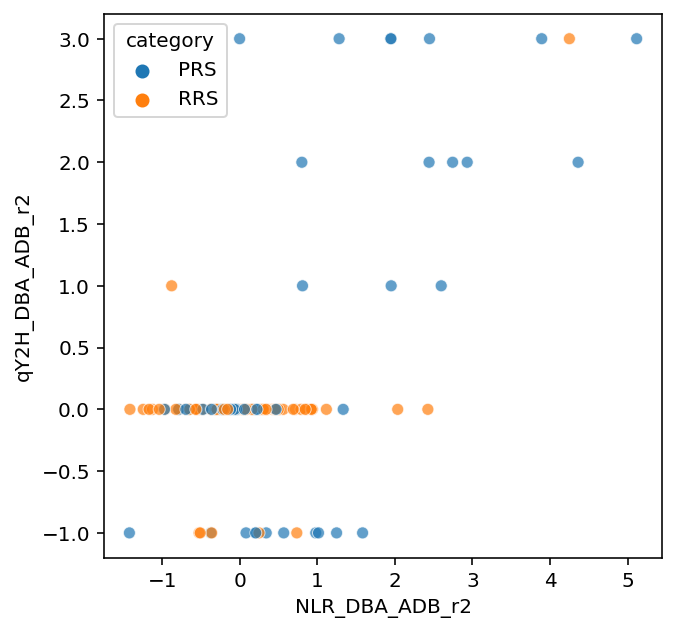

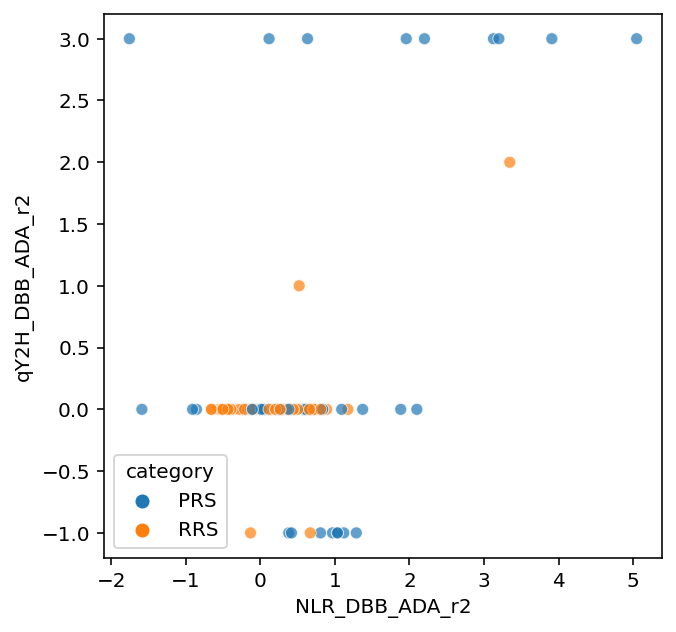

In [23]:
for repeat in ['r1','r2']:
    for orient in ['DBA_ADB','DBB_ADA']:
        df = prsrrsv2

        plt.figure(figsize=(5,5))
        sns.scatterplot(data=df, x=f'NLR_{orient}_{repeat}', y=f'qY2H_{orient}_{repeat}', hue='category', alpha=0.7)

        plt.show()

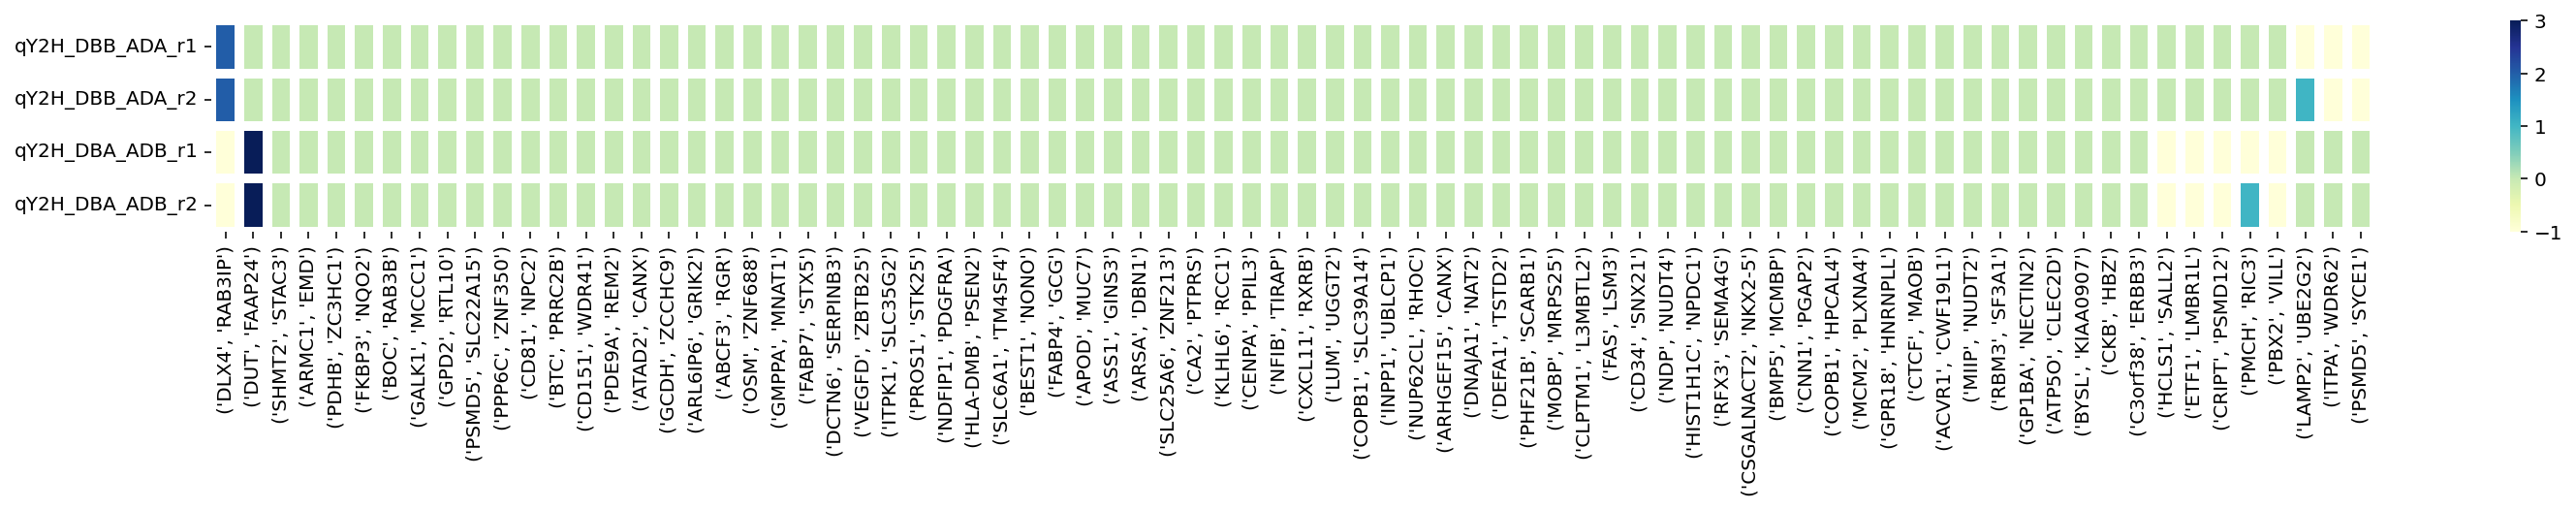

In [24]:
df = prsrrsv2[prsrrsv2.category == 'RRS'].copy()
df['pair']= [tuple(sorted([sa,sb])) for sa,sb in zip(df.symbol_a, df.symbol_b)]

col = ['pair','qY2H_DBB_ADA_r1','qY2H_DBB_ADA_r2','qY2H_DBA_ADB_r1','qY2H_DBA_ADB_r2']

df = df[col].copy()
df.set_index('pair', inplace=True)
#df.rename(columns={c:c[1:] if c != 'pair' else 'pair' for c in df.columns},inplace=True)

df.sort_values(by=['qY2H_DBB_ADA_r1','qY2H_DBA_ADB_r1'], ascending=[False,False], inplace=True)

plt.figure(figsize=(25,2))
sns.heatmap(data=df.T, linewidth=5, cmap='YlGnBu')
plt.xlabel('');
plt.show()

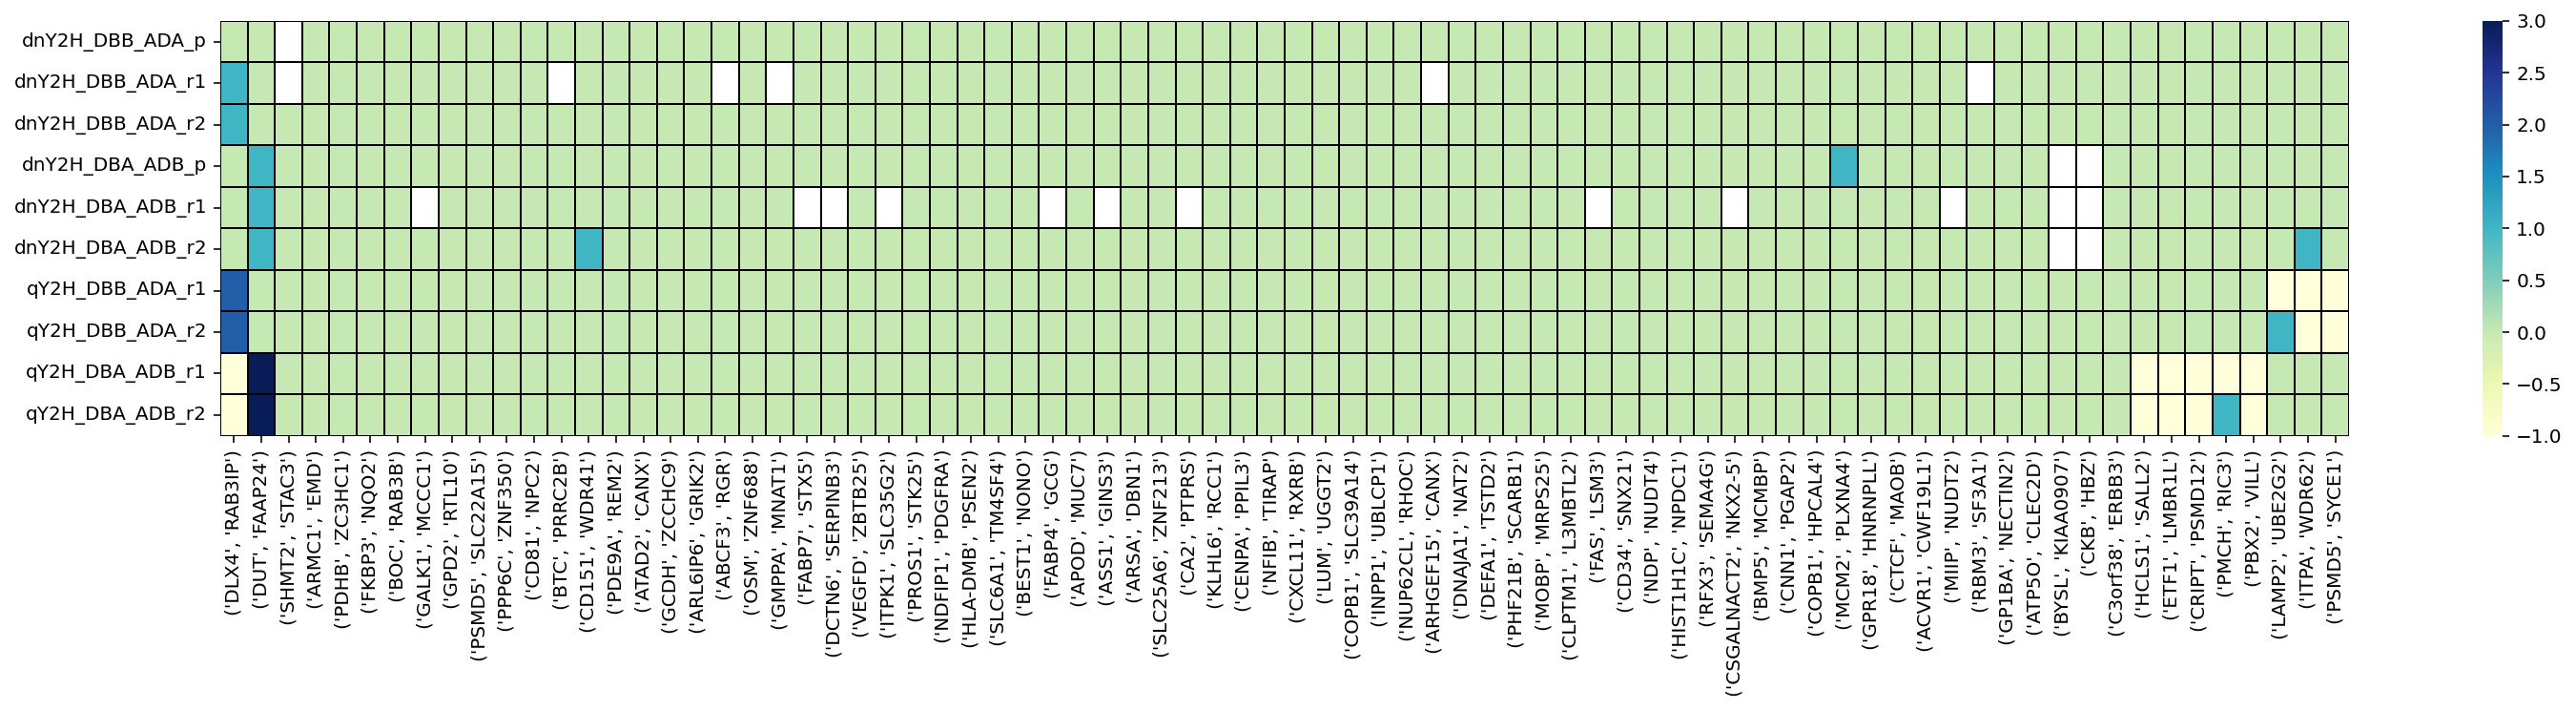

In [25]:
df = prsrrsv2[prsrrsv2.category == 'RRS'].copy()
df['pair']= [tuple(sorted([sa,sb])) for sa,sb in zip(df.symbol_a, df.symbol_b)]

col = ['pair','dnY2H_DBB_ADA_p','dnY2H_DBB_ADA_r1', 'dnY2H_DBB_ADA_r2', 'dnY2H_DBA_ADB_p', 'dnY2H_DBA_ADB_r1', 'dnY2H_DBA_ADB_r2','qY2H_DBB_ADA_r1','qY2H_DBB_ADA_r2','qY2H_DBA_ADB_r1','qY2H_DBA_ADB_r2']

df = df[col].copy()
df.set_index('pair', inplace=True)
#df.rename(columns={c:c[1:] if c != 'pair' else 'pair' for c in df.columns},inplace=True)

df.sort_values(by=['qY2H_DBB_ADA_r1','qY2H_DBA_ADB_r1'], ascending=[False,False], inplace=True)

plt.figure(figsize=(25,4))
sns.heatmap(data=df.T, linewidth=1, cmap='YlGnBu',linecolor='black')
plt.xlabel('');
plt.show()

In [26]:
col = ['orf_ida', 'symbol_a', 'orf_idb', 'symbol_b', 'plate','well',
       'dnY2H_DBA_ADB_r1',
       'dnY2H_DBB_ADA_r1',
       'dnY2H_DBA_ADB_r2', 'dnY2H_DBB_ADA_r2',
       'qY2H_DBB_ADA_r1',
       'qY2H_DBB_ADA_r2', 'qY2H_DBA_ADB_r1', 'qY2H_DBA_ADB_r2']

prsrrsv2.query('''category == 'RRS' and (dnY2H_DBA_ADB_r1 == 1 or dnY2H_DBA_ADB_r2 == 1 or dnY2H_DBB_ADA_r1 == 1 or dnY2H_DBB_ADA_r2 == 1 or qY2H_DBB_ADA_r1 > 0 or qY2H_DBB_ADA_r2 > 0 or qY2H_DBA_ADB_r1 > 0 or qY2H_DBA_ADB_r2 >0)''')[col]





,orf_ida,symbol_a,orf_idb,symbol_b,plate,well,dnY2H_DBA_ADB_r1,dnY2H_DBB_ADA_r1,dnY2H_DBA_ADB_r2,dnY2H_DBB_ADA_r2,qY2H_DBB_ADA_r1,qY2H_DBB_ADA_r2,qY2H_DBA_ADB_r1,qY2H_DBA_ADB_r2
20,6007,CD151,2388,WDR41,1,D04,0.0,0.0,1.0,0.0,0,0,0,0
32,3743,LAMP2,3683,UBE2G2,1,C06,0.0,0.0,0.0,0.0,-1,1,0,0
78,6905,ITPA,7773,WDR62,2,H02,0.0,0.0,1.0,0.0,-1,-1,0,0
79,174,DLX4,472,RAB3IP,2,B03,0.0,1.0,0.0,1.0,2,2,-1,-1
82,10082,DUT,7886,FAAP24,2,E03,1.0,0.0,1.0,0.0,0,0,3,3
99,1160,PMCH,1177,RIC3,2,B06,0.0,0.0,0.0,0.0,0,0,-1,1


In [27]:
col = ['orf_ida', 'symbol_a', 'orf_idb', 'symbol_b', 'plate','well',
       'dnY2H_DBA_ADB_r1',
       'dnY2H_DBB_ADA_r1',
       'dnY2H_DBA_ADB_r2', 'dnY2H_DBB_ADA_r2',
       'qY2H_DBB_ADA_r1',
       'qY2H_DBB_ADA_r2', 'qY2H_DBA_ADB_r1', 'qY2H_DBA_ADB_r2']
table_seq = prsrrsv2.query('''category == 'RRS' and (dnY2H_DBA_ADB_r1 == 1 or dnY2H_DBA_ADB_r2 == 1 or dnY2H_DBB_ADA_r1 == 1 or dnY2H_DBB_ADA_r2 == 1 or qY2H_DBB_ADA_r1 > 0 or qY2H_DBB_ADA_r2 > 0 or qY2H_DBA_ADB_r1 > 0 or qY2H_DBA_ADB_r2 >0)''')[col].copy()
orient_d = {}
table_seq['plate_label'] = [{f"hPRSRRSv2_AD{plate}AxDB{plate}B" for score in [dnY2H_DBB_ADA_r1,dnY2H_DBB_ADA_r2,qY2H_DBB_ADA_r1,qY2H_DBB_ADA_r2] if score > 0}|{f"hPRSRRSv2_AD{plate}BxDB{plate}A" for score in [dnY2H_DBA_ADB_r1,dnY2H_DBA_ADB_r2,qY2H_DBA_ADB_r1,qY2H_DBA_ADB_r2] if score > 0}  for i,(orf_ida,symbol_a,orf_idb,symbol_b,plate,well,dnY2H_DBA_ADB_r1,dnY2H_DBB_ADA_r1,dnY2H_DBA_ADB_r2,dnY2H_DBB_ADA_r2,qY2H_DBB_ADA_r1,qY2H_DBB_ADA_r2,qY2H_DBA_ADB_r1,qY2H_DBA_ADB_r2) in table_seq.iterrows()]
table_seq['plate_label'] = table_seq.plate_label.apply(lambda x: list(x)[0])
table_seq.to_csv('RRS_to_sequence.csv')
table_seq



,orf_ida,symbol_a,orf_idb,symbol_b,plate,well,dnY2H_DBA_ADB_r1,dnY2H_DBB_ADA_r1,dnY2H_DBA_ADB_r2,dnY2H_DBB_ADA_r2,qY2H_DBB_ADA_r1,qY2H_DBB_ADA_r2,qY2H_DBA_ADB_r1,qY2H_DBA_ADB_r2,plate_label
20,6007,CD151,2388,WDR41,1,D04,0.0,0.0,1.0,0.0,0,0,0,0,hPRSRRSv2_AD1BxDB1A
32,3743,LAMP2,3683,UBE2G2,1,C06,0.0,0.0,0.0,0.0,-1,1,0,0,hPRSRRSv2_AD1AxDB1B
78,6905,ITPA,7773,WDR62,2,H02,0.0,0.0,1.0,0.0,-1,-1,0,0,hPRSRRSv2_AD2BxDB2A
79,174,DLX4,472,RAB3IP,2,B03,0.0,1.0,0.0,1.0,2,2,-1,-1,hPRSRRSv2_AD2AxDB2B
82,10082,DUT,7886,FAAP24,2,E03,1.0,0.0,1.0,0.0,0,0,3,3,hPRSRRSv2_AD2BxDB2A
99,1160,PMCH,1177,RIC3,2,B06,0.0,0.0,0.0,0.0,0,0,-1,1,hPRSRRSv2_AD2BxDB2A


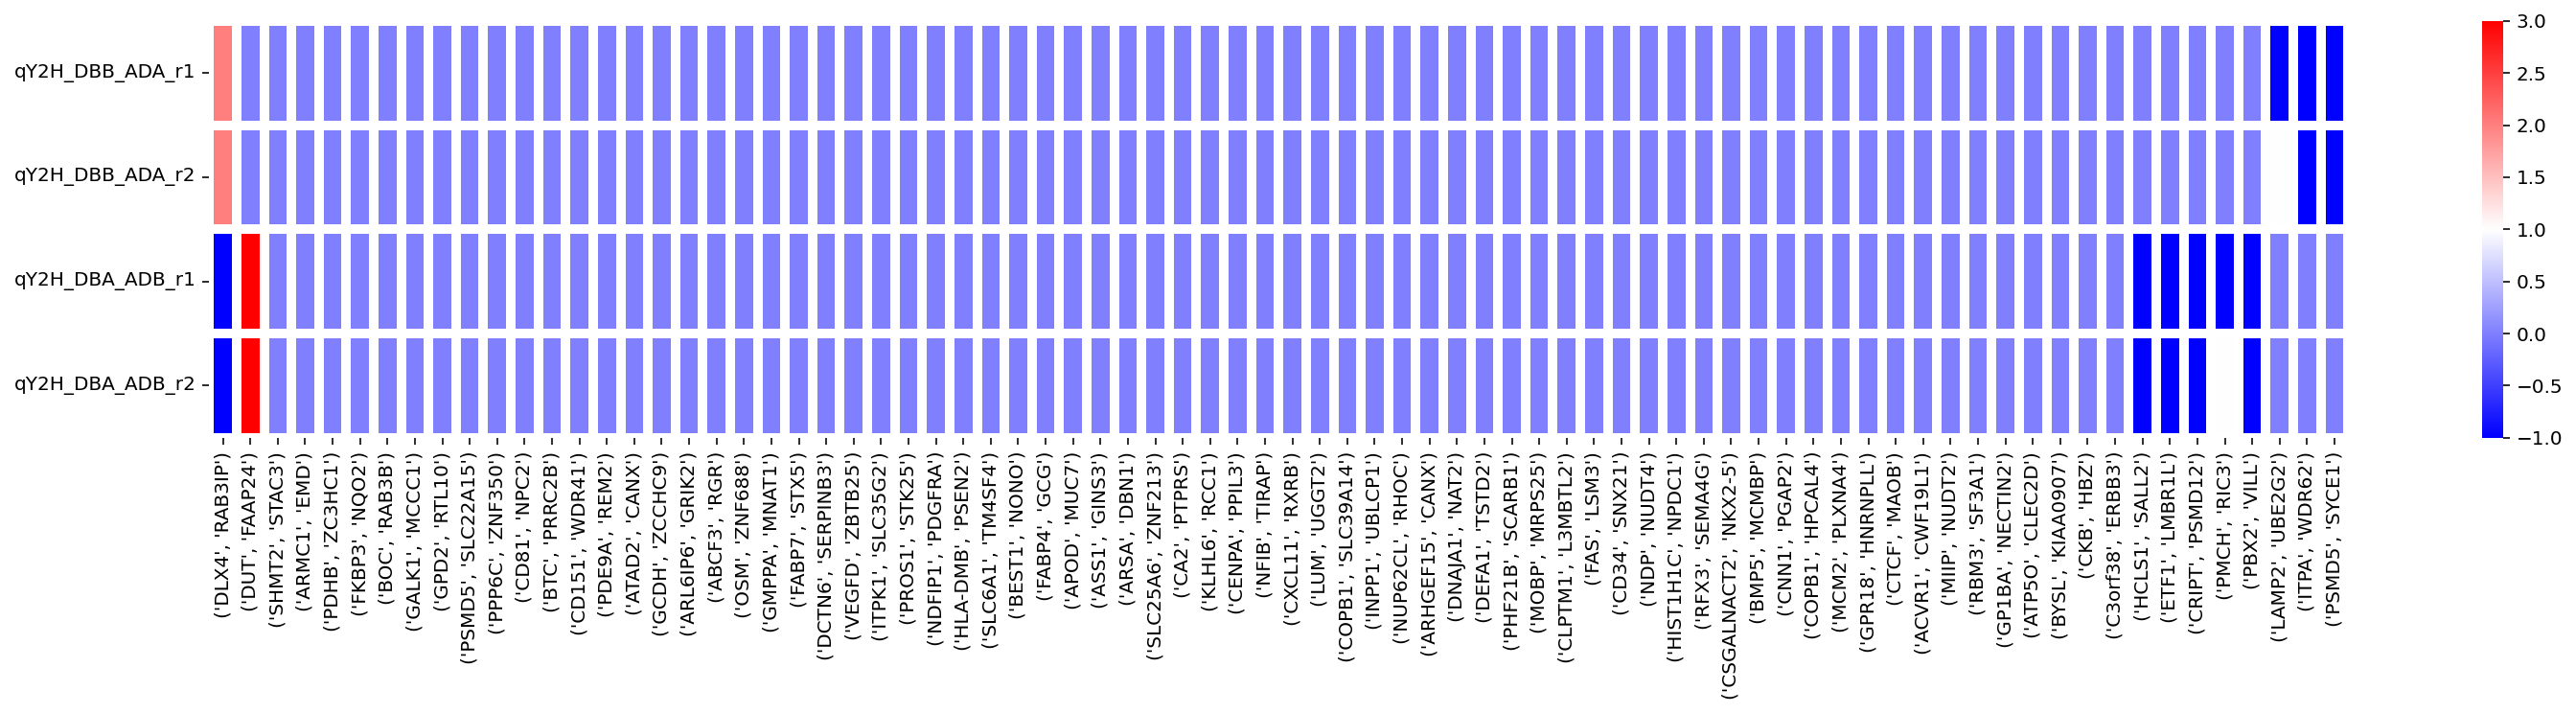

In [28]:
df = prsrrsv2[prsrrsv2.category == 'RRS'].copy()
df['pair']= [tuple(sorted([sa,sb])) for sa,sb in zip(df.symbol_a, df.symbol_b)]

col = ['pair','qY2H_DBB_ADA_r1','qY2H_DBB_ADA_r2','qY2H_DBA_ADB_r1','qY2H_DBA_ADB_r2']

df = df[col].copy()
df.set_index('pair', inplace=True)
#df.rename(columns={c:c[1:] if c != 'pair' else 'pair' for c in df.columns},inplace=True)

df.sort_values(by=['qY2H_DBB_ADA_r1','qY2H_DBA_ADB_r1'], ascending=[False,False], inplace=True)

plt.figure(figsize=(25,4))
sns.heatmap(data=df.T, linewidth=5, cmap='bwr')
plt.xlabel('');
plt.show()

## Allele and KD retest

In [29]:
kd_df = GetDF('bioinfo_georges','kd_wt_retest')
#kd_d = dict(zip(kd_df[['orf_id_1','orf_id_2']].apply(tuple, axis=1),kd_df.Kd_Ki_IC50_M))
kd_d = dict(zip(kd_df[['orf_id_1','orf_id_2']].apply(lambda x: tuple(sorted([x[0],x[1]])), axis=1),kd_df.Kd_Ki_IC50_M))
kd_df.head()

,retest_id,orf_id_1,orf_id_2,ad_orf_id,db_orf_id,Protein_1_AC,Protein_2_AC,kd_value,PDB_code,Affinity_Data,Kd_Ki_IC50_M,dG_kcal_mol,pKd_pKi_pIC50,n_same_char_1,n_same_char_2,identity_1,identity_2,orf_alignment_1,frag_alignment_1,orf_alignment_2,frag_alignment_2,ad_cen_huri_plate,ad_cen_huri_well,db_cen_huri_plate,db_cen_huri_well,ad_inoculated_plate,ad_inoculated_well,db_inoculated_plate,db_inoculated_well,retest_pla,retest_pos,standard_batch,retest_batch,cp_pwt_db_plate,cp_pwt_db_well,cp_pwt_ad_plate,cp_pwt_ad_well
0,1,172.0,72168.0,172,72168,O75909,Q9NYV4,kd >= 1.4050000000000002e-07,4nst,IC50=1.37uM,1.370000e-06,-8.31643,5.86000,267.0,350.0,0.754237,0.236327,-MKENKENSSPSVTSANLDHTKPCWYWDKKDLAHTPSQLEGLDPAT...,GMKENKENSSPSVTSANLDHTKPCWYWDKKDLAHTPSQLEGLDPAT...,MPNSERHGGKKDGSGGASGTLQPSSGGGSSNSRERHRLVSKHKRHK...,----------------------------------------------...,RhIY8ADG03_09,C12,RhIY8DBG02_17,C02,KdWT_AD_1,B11,KdWT_DB_1,H08,1,A01,KdWTpwt,KdWTpwt,KdWTpwt_DB_1,A01,KdWTpwt_AD_1,A01
1,2,13088.0,71620.0,13088,71620,P03973,P08246,kd < 1.4050000000000002e-07,2z7f,IC50=13nM,1.300000e-08,-11.18550,7.88606,50.0,218.0,0.378788,0.816479,MKSSGLFPFLVLLALGTLAPWAVEGSGKSFKAGVCPPKKSAQCLRY...,----------------------------------------------...,MTLGRRLACLFLACVLPALLLGGTALASEIVGGRRARPHAWPFMVS...,-----------------------------IVGGRRARPHAWPFMVS...,RhIY8ADG02_05,D03,RhIY8DBG04_06,F11,KdWT_AD_1,G05,KdWT_DB_2,D03,1,B01,KdWTpwt,KdWTpwt,KdWTpwt_DB_1,B01,KdWTpwt_AD_1,B01
2,3,14932.0,5597.0,14932,5597,P01579,P15260,kd < 1.4050000000000002e-07,1fg9,Kd=0.10nM,1.000000e-10,-14.18390,10.00000,133.0,245.0,0.801205,0.501023,MKYTSYILAFQLCIVLGSLGCYCQDPYVKEAENLKKYFNAGHSDVA...,----------------------MQDPYVKEAENLKKYFNAGHSDVA...,MALLFLLPLVMQGVSRAEMGTADLGPSSVPTPTNVTIESYNMNPIV...,-----------------EMGTADLGPSSVPTPTNVTIESYNMNPIV...,RhIY8ADG06_11,E12,RhIY8DBG01_09,F02,KdWT_AD_2,F12,KdWT_DB_1,B03,1,C01,KdWTpwt,KdWTpwt,KdWTpwt_DB_1,C01,KdWTpwt_AD_1,C01
3,4,2023.0,13674.0,2023,13674,P05546,P00734,kd < 1.4050000000000002e-07,1jmo,Kd=0.115uM,1.150000e-07,-9.84265,6.94000,478.0,259.0,0.957916,0.416399,MKHSLNALLIFLIITSAWGGSKGPLDQLEKGGETAQSADPQWEQLN...,-------------------GSKGPLDQLEKGGETAQSADPQWEQLN...,MAHVRGLQLPGCLALAALCSLVHSQHVFLAPQQARSLLQRVRRANT...,----------------------------------------------...,RhIY8ADG02_08,D08,RhIY8DBG05_12,B02,KdWT_AD_1,H06,KdWT_DB_2,E08,1,D01,KdWTpwt,KdWTpwt,KdWTpwt_DB_1,D01,KdWTpwt_AD_1,D01
4,5,7442.0,100080624.0,7442,100080624,P61586,Q13459,kd < 1.4050000000000002e-07,5hpy,Kd=0.13uM,1.300000e-07,-9.76713,6.89000,178.0,228.0,0.922280,0.105702,----MAAIRKKLVIVGDGACGKTCLLIVFSKDQFPEVYVPTVFENY...,GPGSEFAIRKKLVIVGDGACGKTCLLIVNSKDQFPEVYVPTVFENY...,MSVKEAGSSGRREQAAYHLHIYPQLSTTESQASCRVTATKDSTTSD...,----------------------------------------------...,RhIY8ADG03_04,B02,RhIY8DBG00_07,F02,KdWT_AD_1,F09,KdWT_DB_1,G01,1,E01,KdWTpwt,KdWTpwt,KdWTpwt_DB_1,E01,KdWTpwt_AD_1,E01


In [30]:
import pandas as pd

retest_df = pd.read_csv('NY2H_APWT_summary_file.csv')


retest_df.head()

,db_orf_id,db_symbol,db_mut_id,ad_orf_id,ad_symbol,assay_id,retest_type,db_source_plate,db_source_well,ad_source_plate,ad_source_well,dest_well_id,dest_well,dest_pla_id,db_dest_pla,ad_dest_pla
0,1739.0,BMPR1A,0.0,100014367.0,BMP2,1.0,kd,NY2H_KdGDDh02,A07,NY2H_KdGDAh04,A01,1,A01,1,NY2H_APWT_DB_01,NY2H_APWT_AD_01
1,1739.0,BMPR1A,0.0,0.0,empty_ad1,1.0,kd,NY2H_KdGDDh02,A07,ctrl_pla,A01,2,B01,1,NY2H_APWT_DB_01,NY2H_APWT_AD_01
2,100014367.0,BMP2,0.0,1739.0,BMPR1A,1.0,kd,NY2H_KdGDDh04,A01,NY2H_KdGDAh02,A07,3,C01,1,NY2H_APWT_DB_01,NY2H_APWT_AD_01
3,100014367.0,BMP2,0.0,0.0,empty_ad1,1.0,kd,NY2H_KdGDDh04,A01,ctrl_pla,A01,4,D01,1,NY2H_APWT_DB_01,NY2H_APWT_AD_01
4,NaN,NaN,NaN,NaN,NaN,NaN,secret_code,NaN,NaN,NaN,NaN,5,E01,1,NY2H_APWT_DB_01,NY2H_APWT_AD_01


In [31]:
retest_df.query("db_mut_id > 0").db_mut_id.nunique()

771

In [32]:
retest_df = pd.read_csv('NY2H_APWT_summary_file.csv')
retest_df = retest_df[retest_df.dest_pla_id < 79].copy()
retest_df['RLU'] = [res[pla,well] for pla,well in zip(retest_df.dest_pla_id, retest_df.dest_well)]
retest_df['RLU_log10'] = retest_df.RLU.apply(np.log10)
retest_df['empty_well'] = [False if pla not in empty_well_retest_d else well in empty_well_retest_d[pla] for pla,well in zip(retest_df.dest_pla_id, retest_df.dest_well)]
retest_df['invalid'] = retest_df.empty_well | (retest_df.RLU_log10 < 2.85)

retest_df.head()

,db_orf_id,db_symbol,db_mut_id,ad_orf_id,ad_symbol,assay_id,retest_type,db_source_plate,db_source_well,ad_source_plate,ad_source_well,dest_well_id,dest_well,dest_pla_id,db_dest_pla,ad_dest_pla,RLU,RLU_log10,empty_well,invalid
0,1739.0,BMPR1A,0.0,100014367.0,BMP2,1.0,kd,NY2H_KdGDDh02,A07,NY2H_KdGDAh04,A01,1,A01,1,NY2H_APWT_DB_01,NY2H_APWT_AD_01,12671,4.102811,False,False
1,1739.0,BMPR1A,0.0,0.0,empty_ad1,1.0,kd,NY2H_KdGDDh02,A07,ctrl_pla,A01,2,B01,1,NY2H_APWT_DB_01,NY2H_APWT_AD_01,18984,4.278388,False,False
2,100014367.0,BMP2,0.0,1739.0,BMPR1A,1.0,kd,NY2H_KdGDDh04,A01,NY2H_KdGDAh02,A07,3,C01,1,NY2H_APWT_DB_01,NY2H_APWT_AD_01,23360,4.368473,False,False
3,100014367.0,BMP2,0.0,0.0,empty_ad1,1.0,kd,NY2H_KdGDDh04,A01,ctrl_pla,A01,4,D01,1,NY2H_APWT_DB_01,NY2H_APWT_AD_01,27489,4.439159,False,False
4,NaN,NaN,NaN,NaN,NaN,NaN,secret_code,NaN,NaN,NaN,NaN,5,E01,1,NY2H_APWT_DB_01,NY2H_APWT_AD_01,55,1.740363,True,True


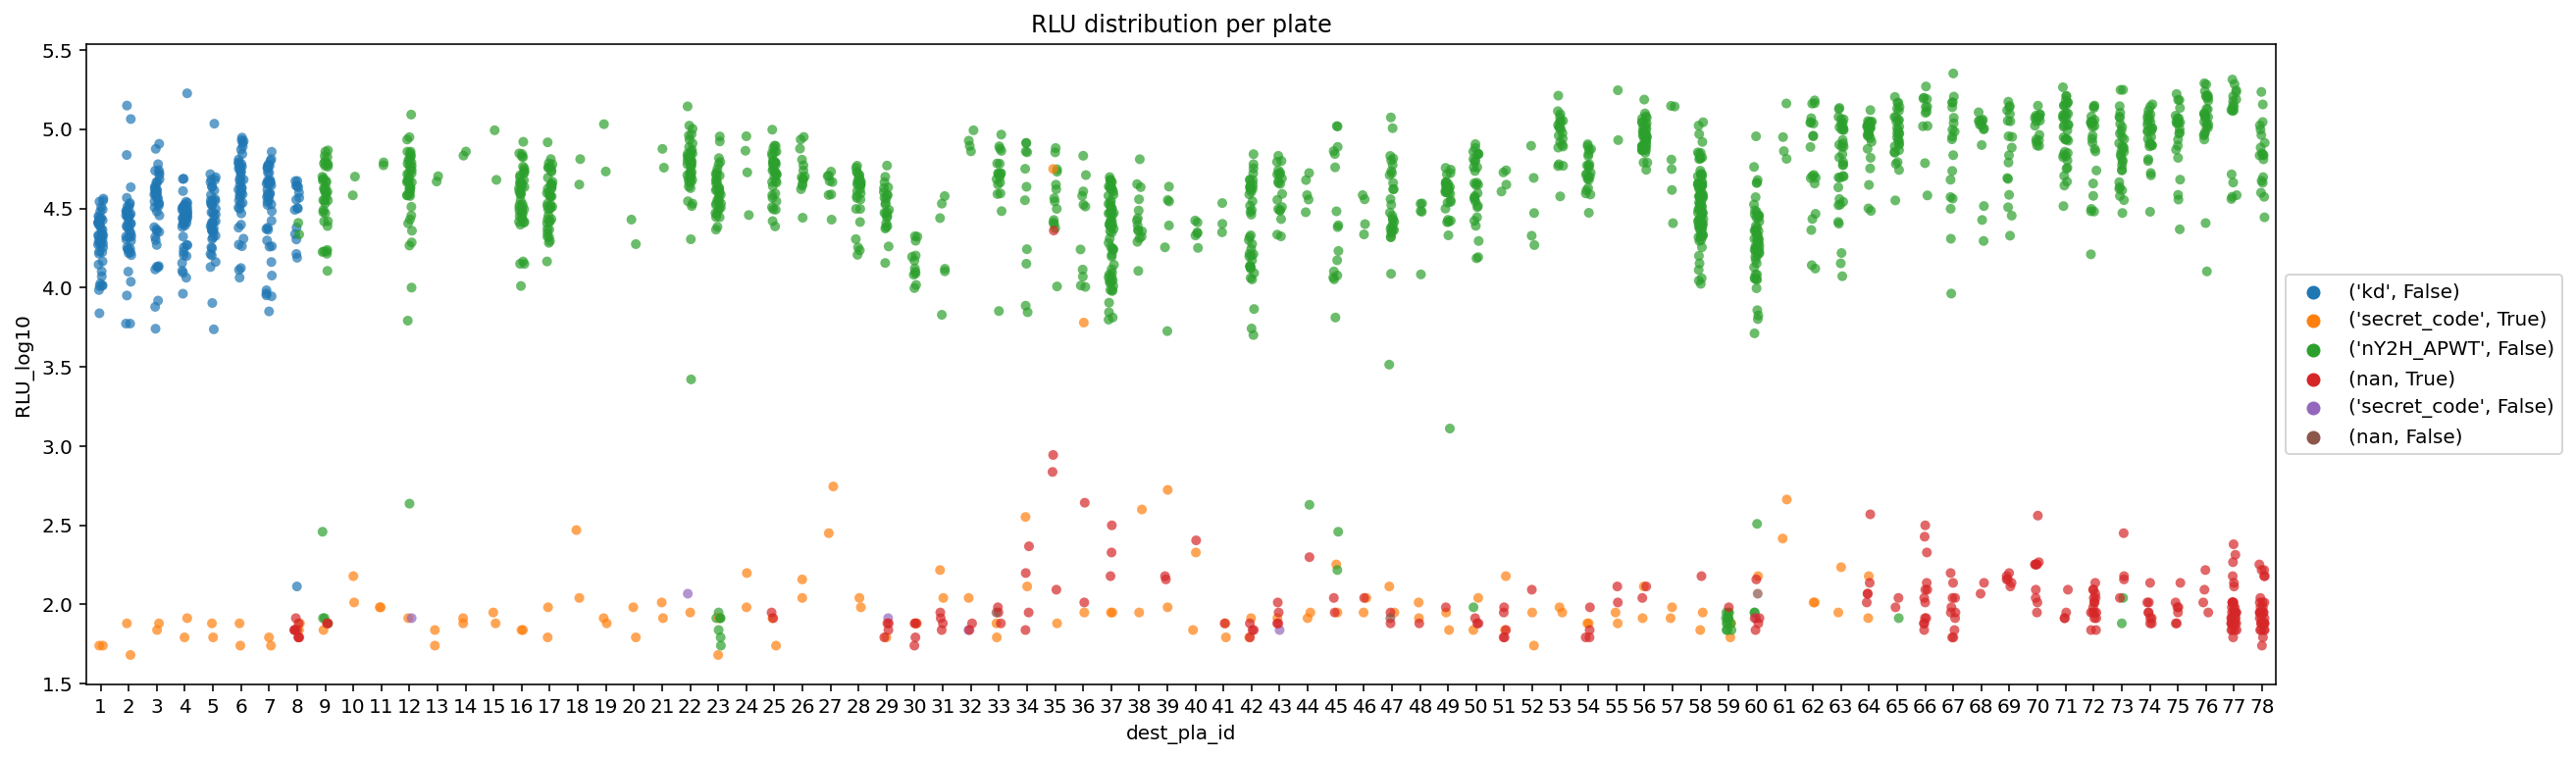

In [33]:
plt.figure(figsize=(20,6))
plt.title('RLU distribution per plate')
sns.stripplot(data=retest_df.query("ad_symbol.str.contains('empty', na=True)"),
              x='dest_pla_id',y='RLU_log10',
              hue=retest_df.query("ad_symbol.str.contains('empty', na=True)")[['retest_type', 'empty_well']].apply(tuple, axis=1),
              alpha=0.7
             )
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

plt.show()

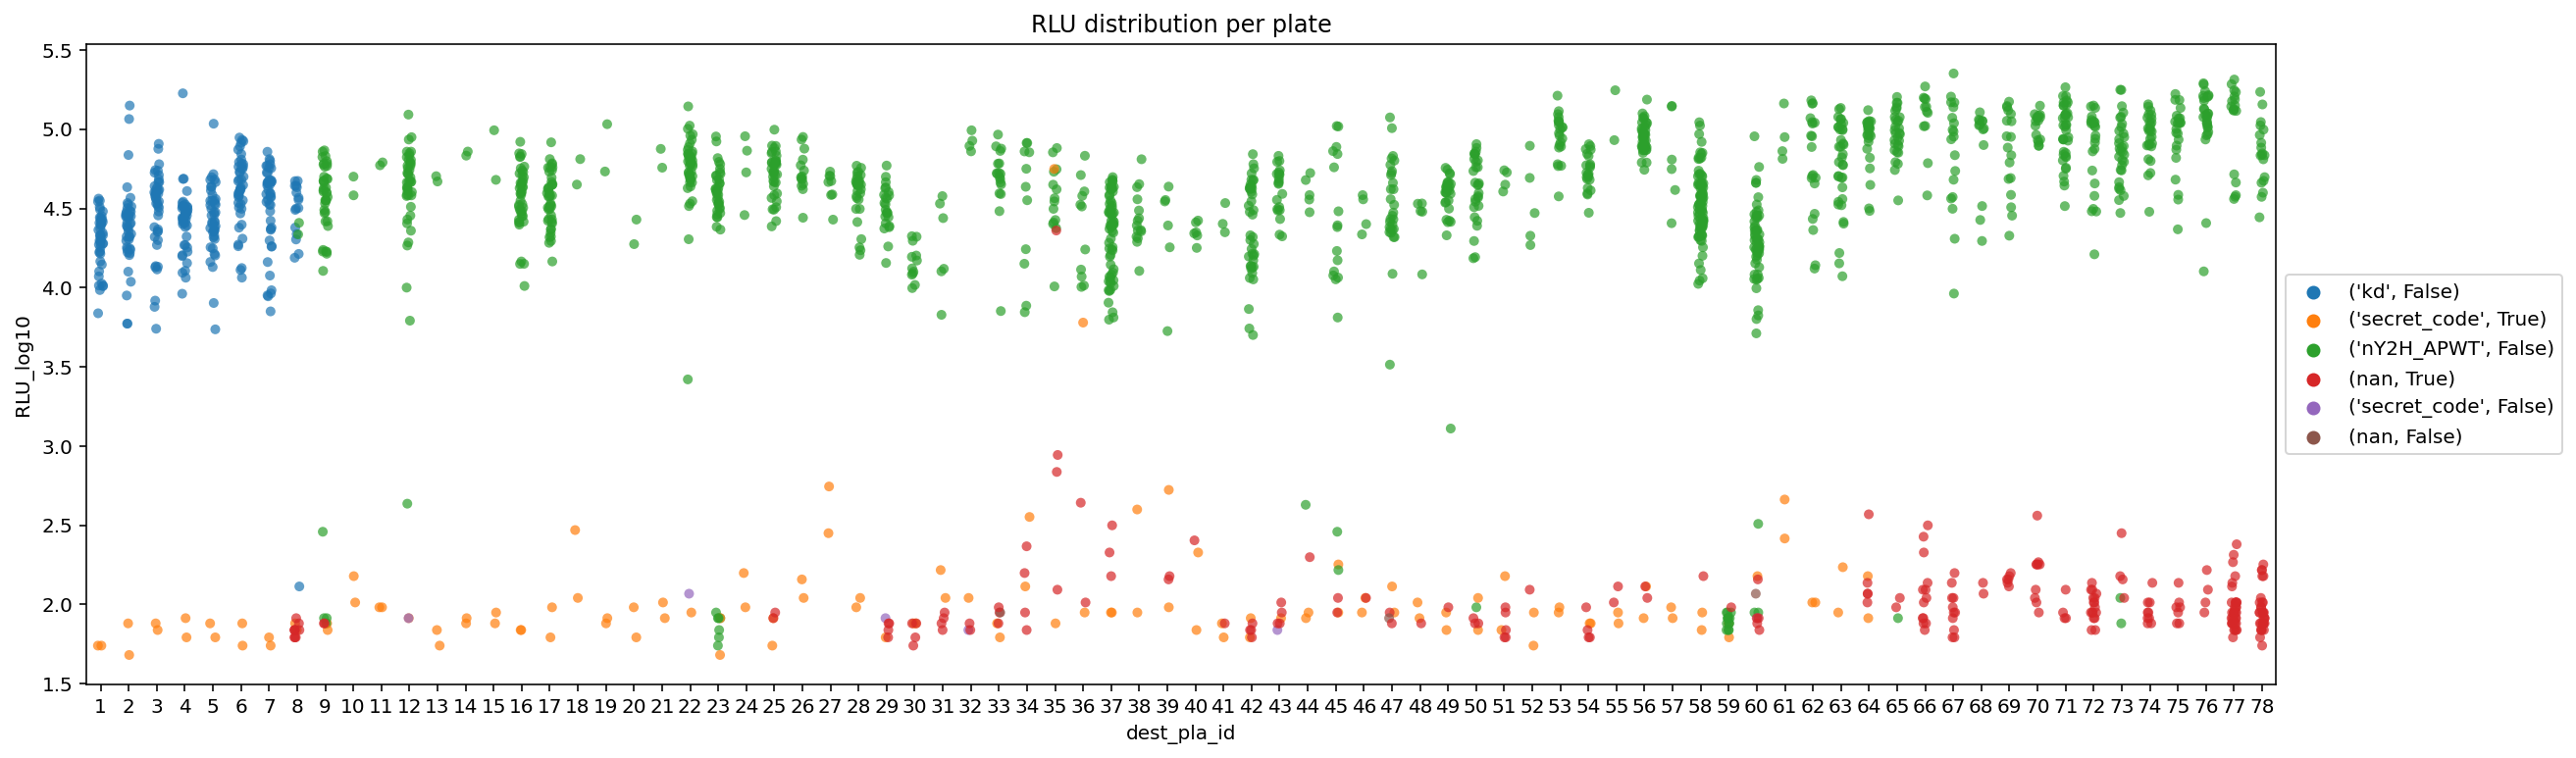

In [34]:
plt.figure(figsize=(20,6))
plt.title('RLU distribution per plate')
sns.stripplot(data=retest_df.query("ad_symbol.str.contains('empty', na=True)"),
              x='dest_pla_id',y='RLU_log10',
              hue=retest_df.query("ad_symbol.str.contains('empty', na=True)")[['retest_type', 'empty_well']].apply(tuple, axis=1),
              alpha=0.7
             )
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

plt.show()

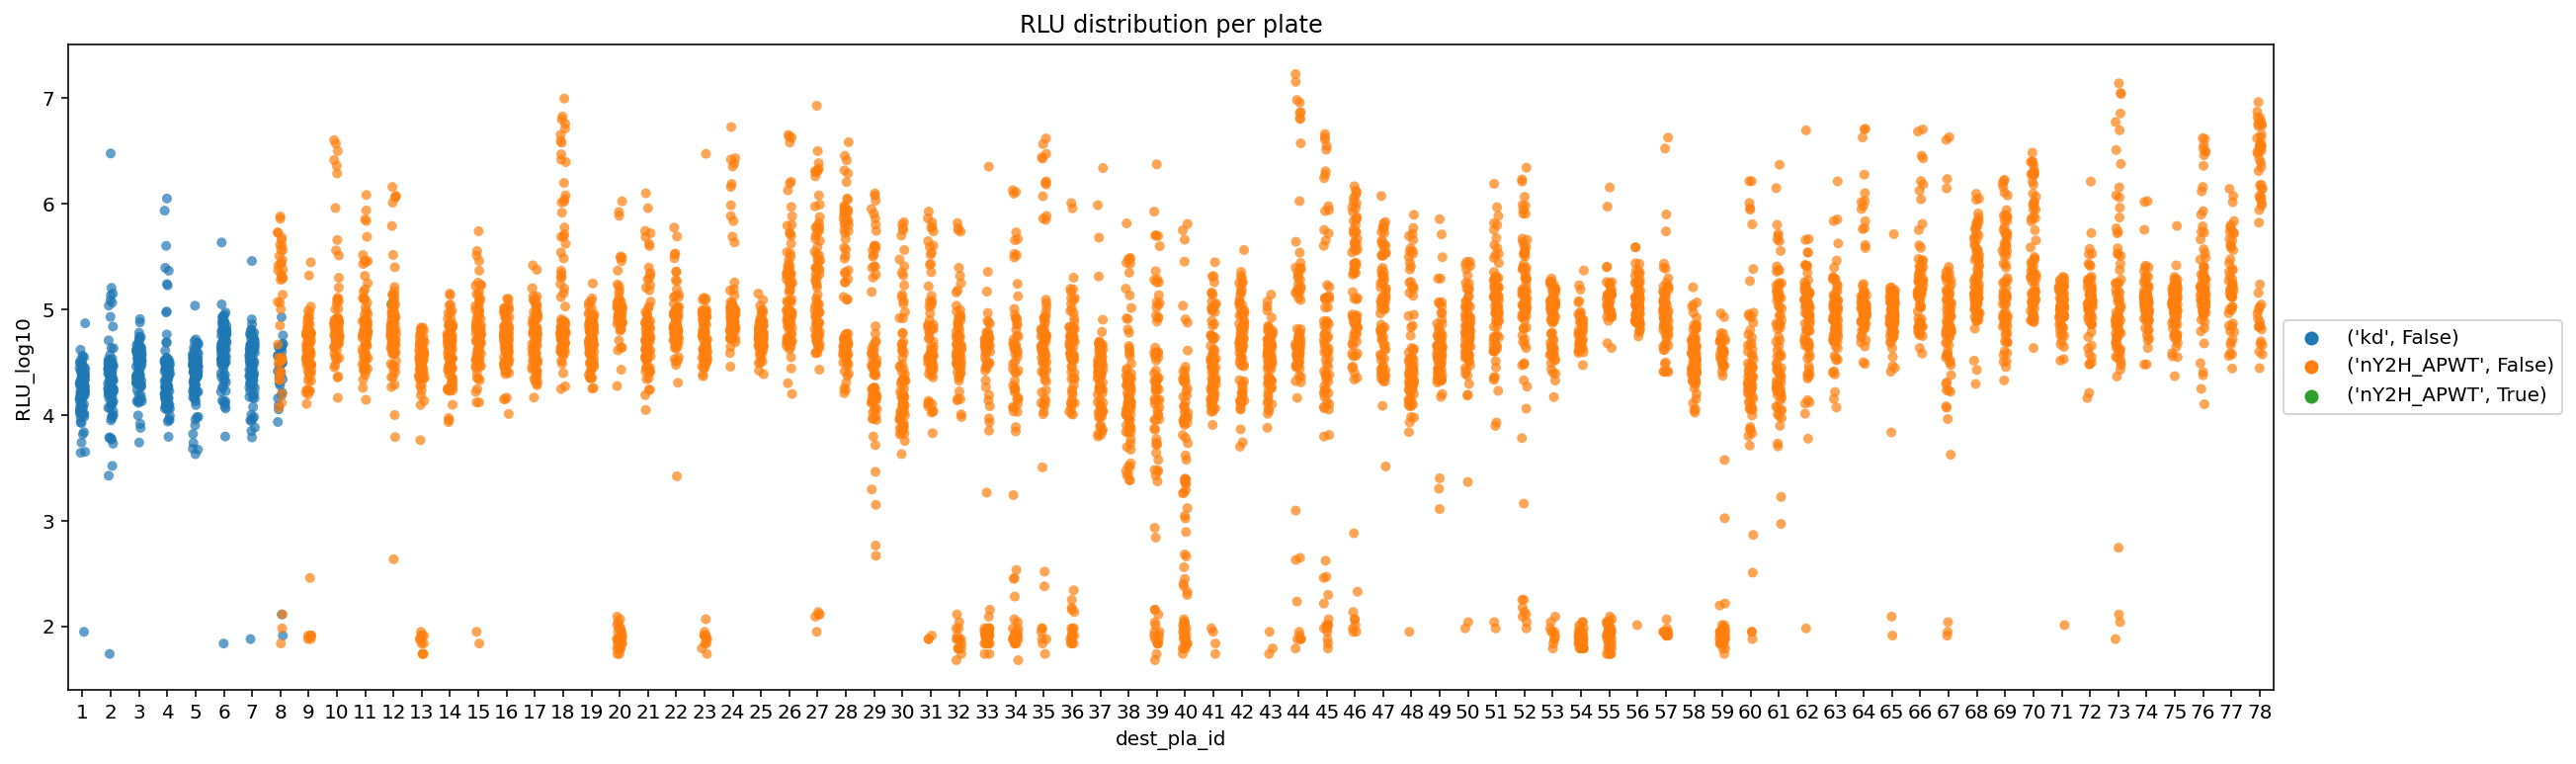

In [35]:
plt.figure(figsize=(20,6))
plt.title('RLU distribution per plate')
sns.stripplot(data=retest_df.query("retest_type.isin(['kd','nY2H_APWT'])"),
              x='dest_pla_id',y='RLU_log10',
              hue=retest_df.query("retest_type.isin(['kd','nY2H_APWT'])")[['retest_type', 'empty_well']].apply(tuple, axis=1),
              alpha=0.7
             )
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

plt.show()

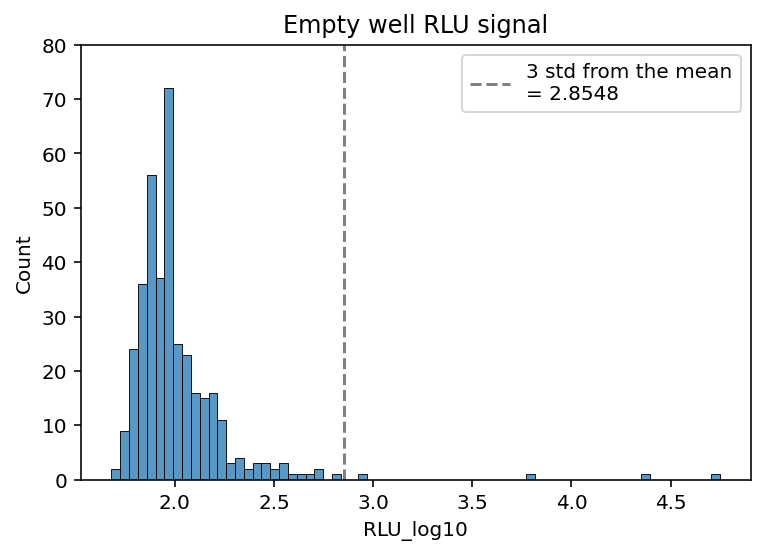

In [36]:
empty_wells = "empty_well == True and (retest_type == 'secret_code' or retest_type != retest_type)"

mean_ew_rlu = retest_df.query(empty_wells).RLU_log10.mean()
std_ew_rlu = np.std(retest_df.query(empty_wells).RLU_log10)

plt.figure()
plt.title('Empty well RLU signal')
sns.histplot(data=retest_df.query(empty_wells),x='RLU_log10')
plt.vlines(x=(3*std_ew_rlu)+mean_ew_rlu, ymin=0, ymax=80, label=f'3 std from the mean\n= {round((3*std_ew_rlu)+mean_ew_rlu,4)}', linestyles='--', color='grey')
plt.legend()
plt.ylim(0,80)
plt.show()

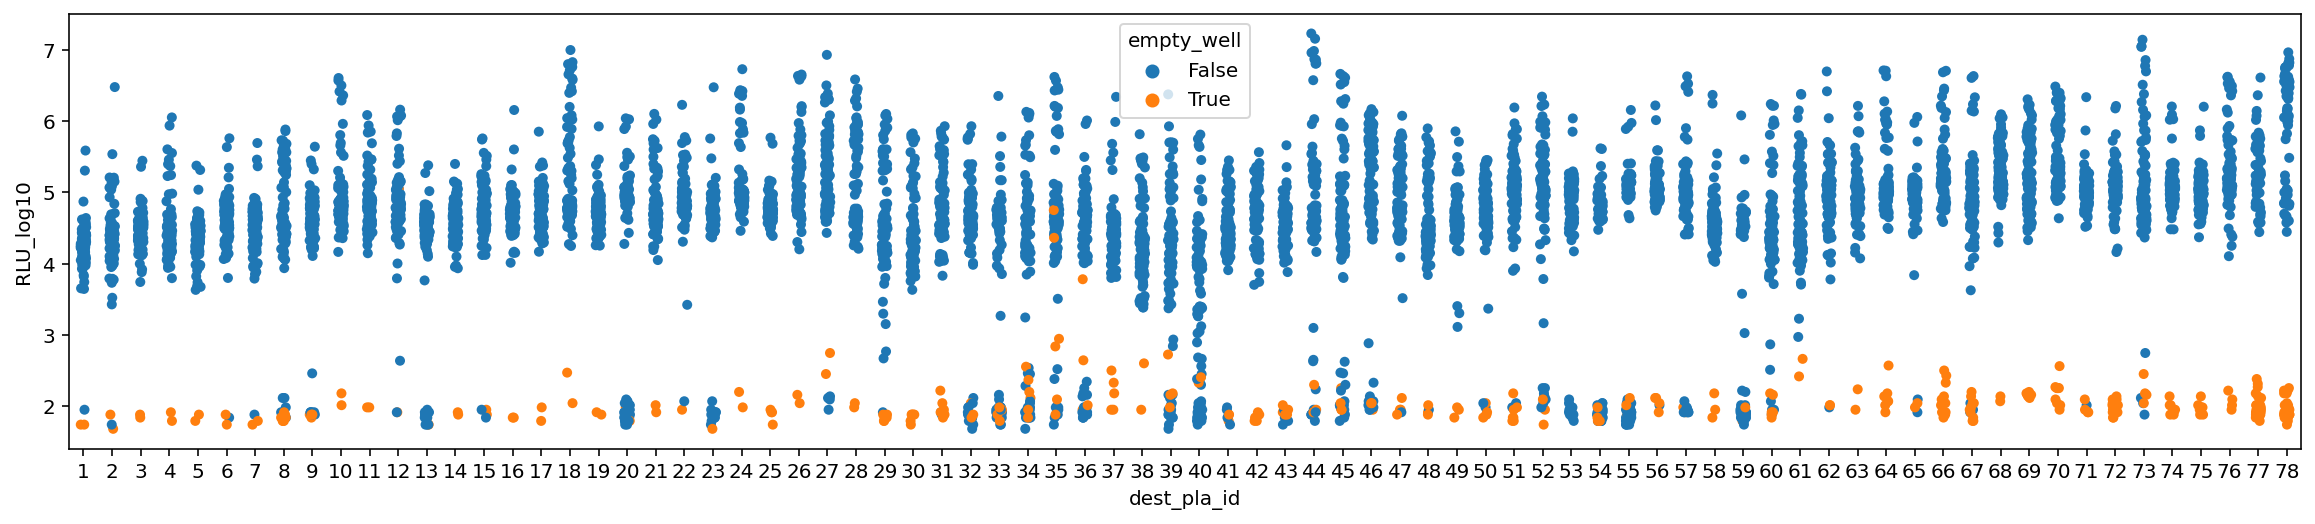

In [37]:
plt.figure(figsize=(20,4))
sns.stripplot(data=retest_df,
            x='dest_pla_id',
            y='RLU_log10',
              hue='empty_well'
           )

plt.show()

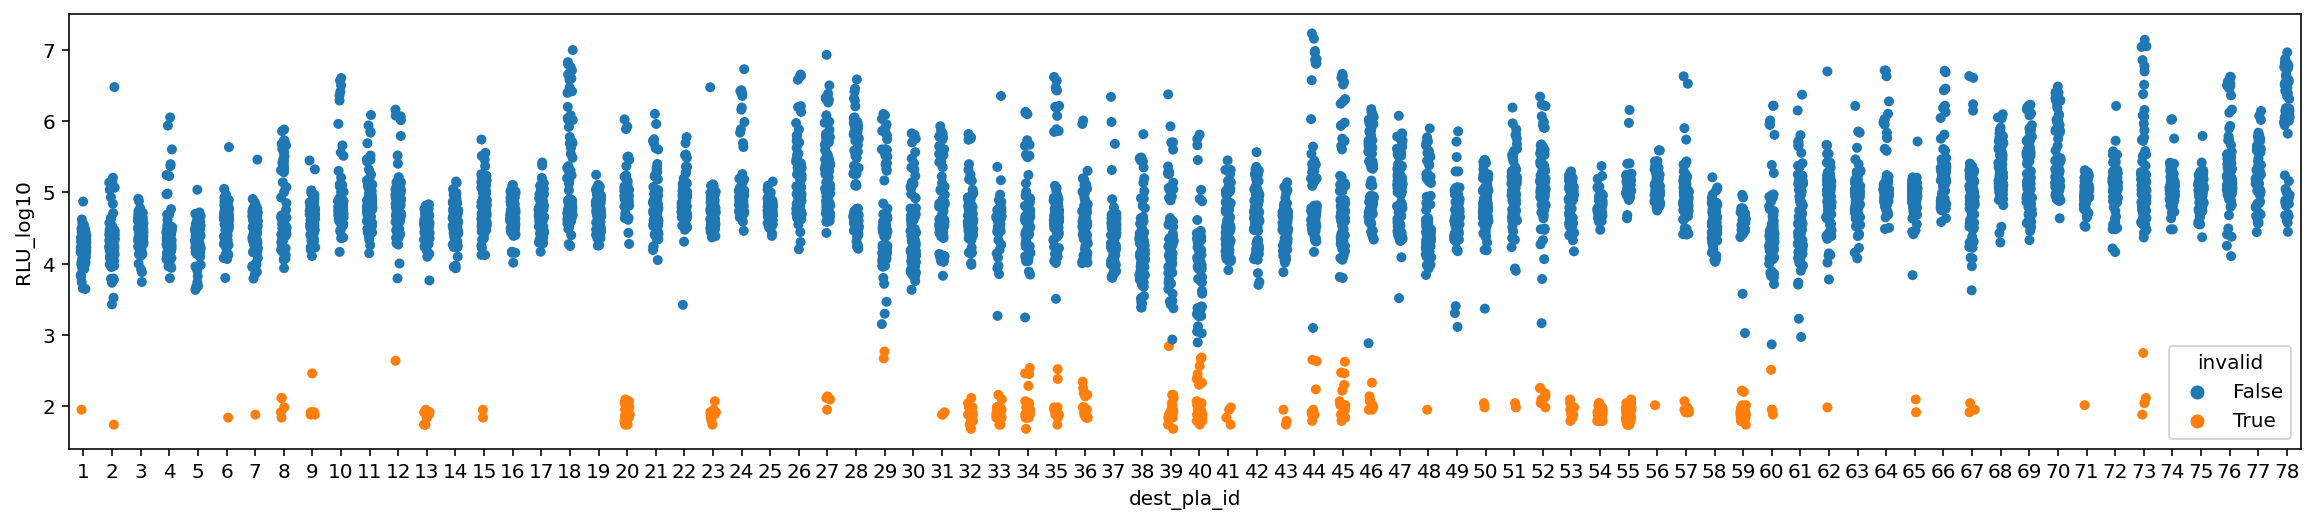

In [38]:
plt.figure(figsize=(20,4))
sns.stripplot(data=retest_df.query("retest_type.isin(['kd','nY2H_APWT'])"),
            x='dest_pla_id',
            y='RLU_log10',
              hue='invalid'
           )

plt.show()

In [39]:
ead_d = dict()
col = ['db_orf_id','db_mut_id','assay_id','RLU']
for i, (db_orf_id,db_mut_id,assay_id,RLU) in retest_df.query('ad_orf_id == 0 and empty_well == False and invalid == False')[col].iterrows():
    ead_d[(db_orf_id,db_mut_id,assay_id)] = RLU


In [40]:
col = ['db_orf_id', 'db_symbol', 'db_mut_id', 'ad_orf_id', 'ad_symbol','assay_id', 'retest_type', 'RLU', 'RLU_log10','empty_well','invalid']

normalized_df = retest_df.query("retest_type.isin(['nY2H_APWT','kd']) and ad_orf_id != 0")[col].copy()
normalized_df['RLU_ctrl'] = [ead_d[db_orf_id,db_mut_id,assay_id] if (db_orf_id,db_mut_id,assay_id) in ead_d else np.nan  for db_orf_id,db_mut_id,assay_id in zip(normalized_df.db_orf_id, normalized_df.db_mut_id, normalized_df.assay_id)]
normalized_df['NLR'] = [np.log2(rlu/ctrl) if not invalid and ctrl == ctrl else np.nan for rlu,ctrl,invalid in zip(normalized_df.RLU, normalized_df.RLU_ctrl, normalized_df.invalid)]

#detection threshold:  1.7573820895430956
normalized_df['detected'] = normalized_df.NLR >= 1.7573820895430956
#kd_d
normalized_df['Kd'] = [kd_d[tuple(sorted([db,ad]))] if tuple(sorted([db,ad])) in kd_d else np.nan for db,ad in zip(normalized_df.db_orf_id, normalized_df.ad_orf_id)]
normalized_df['Kd'] = [np.log10(kd_d[tuple(sorted([db,ad]))]) if tuple(sorted([db,ad])) in kd_d else np.nan for db,ad in zip(normalized_df.db_orf_id, normalized_df.ad_orf_id)]

normalized_df.head()

,db_orf_id,db_symbol,db_mut_id,ad_orf_id,ad_symbol,assay_id,retest_type,RLU,RLU_log10,empty_well,invalid,RLU_ctrl,NLR,detected,Kd
0,1739.0,BMPR1A,0.0,100014367.0,BMP2,1.0,kd,12671,4.102811,False,False,18984.0,-0.583254,False,-8.309804
2,100014367.0,BMP2,0.0,1739.0,BMPR1A,1.0,kd,23360,4.368473,False,False,27489.0,-0.234814,False,-8.309804
5,54387.0,FLT3LG,0.0,54530.0,FLT3,1.0,kd,11682,4.067517,False,False,16394.0,-0.488881,False,-7.397940
7,13530.0,LCN2,0.0,55203.0,FN1,1.0,kd,12760,4.105851,False,False,10219.0,0.320374,False,-8.238824
11,55203.0,FN1,0.0,13530.0,LCN2,1.0,kd,22948,4.360745,False,False,23648.0,-0.043350,False,-8.238824


In [41]:
normalized_df.to_csv('processed_data/nanoY2H_processed_df.csv',index=False)
rrs_df.to_csv('processed_data/hsRRSv2_for_setting_detection_threshold.csv',index=False)
prsrrsv2.to_csv('processed_data/hsPRSRRSv2.csv',index=False)
#normalized_df.to_csv('processed_data/nanoY2H_processed_df.csv',index=False)

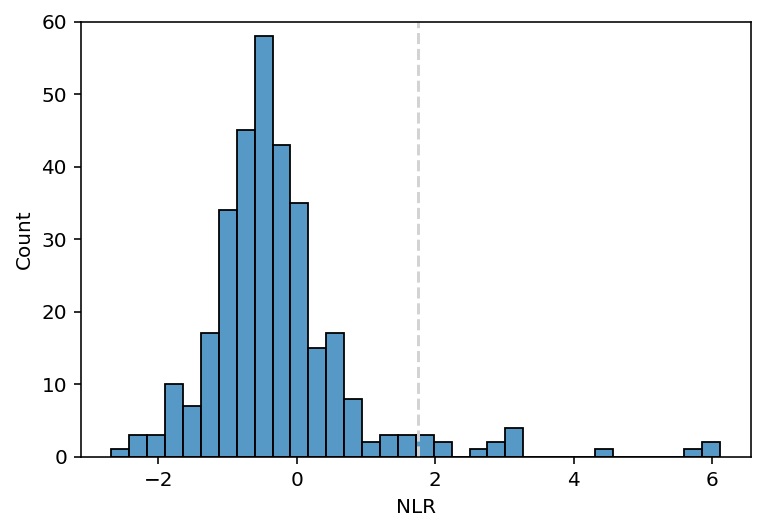

In [42]:
sns.histplot(data=normalized_df.query("retest_type == 'kd'"), x='NLR')

plt.vlines(x=1.7573820895430956, ymin=0, ymax=60, linestyles='--', color='lightgrey')
plt.ylim(0,60);

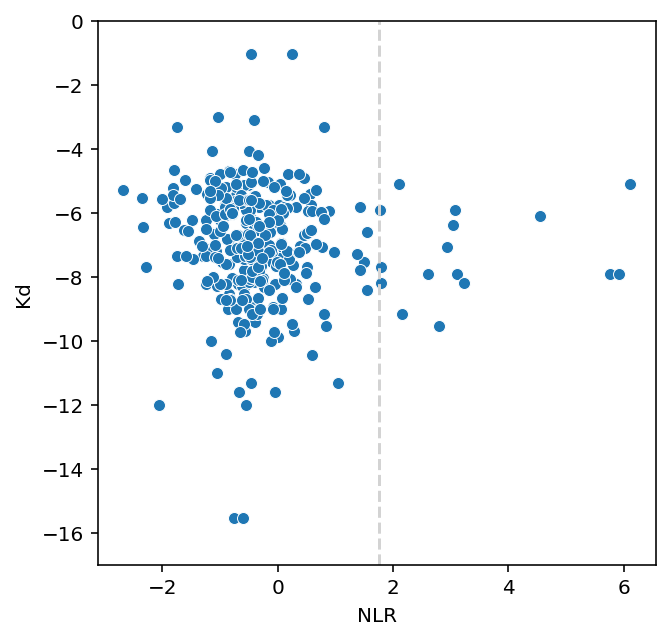

In [43]:
plt.figure(figsize=(5,5))
sns.scatterplot(data=normalized_df.query("retest_type == 'kd'"), x='NLR', y='Kd')
plt.vlines(x=1.7573820895430956, ymin=-17, ymax=0, linestyles='--', color='lightgrey')

plt.ylim(-17,0)
plt.show()

In [44]:
normalized_df.query("retest_type == 'kd' and NLR > 1.757")

,db_orf_id,db_symbol,db_mut_id,ad_orf_id,ad_symbol,assay_id,retest_type,RLU,RLU_log10,empty_well,invalid,RLU_ctrl,NLR,detected,Kd
63,4452.0,SF1,0.0,4551.0,U2AF2,1.0,kd,73978,4.869103,False,False,9663.0,2.936553,True,-7.075721
130,596.0,MAGOH,0.0,501.0,RBM8A,1.0,kd,136342,5.134630,False,False,30553.0,2.157844,True,-9.154902
184,4340.0,TRADD,0.0,9637.0,TRAF2,1.0,kd,2988560,6.475462,False,False,43095.0,6.115786,True,-5.107905
186,9637.0,TRAF2,0.0,4340.0,TRADD,1.0,kd,121766,5.085526,False,False,28300.0,2.105237,True,-5.107905
213,100010572.0,KPNB1,0.0,231.0,RAN,1.0,kd,38188,4.581927,False,False,5508.0,2.793519,True,-9.522879
296,71965.0,CSNK2B,0.0,100080348.0,CSNK2A1,1.0,kd,247768,5.394045,False,False,28540.0,3.117933,True,-7.899629
298,100080348.0,CSNK2A1,0.0,71965.0,CSNK2B,1.0,kd,860054,5.934526,False,False,15838.0,5.762965,True,-7.899629
300,6699.0,CSNK2A1,0.0,71965.0,CSNK2B,1.0,kd,1121013,6.049611,False,False,18585.0,5.914521,True,-7.899629
302,71965.0,CSNK2B,0.0,6699.0,CSNK2A1,1.0,kd,174115,5.240836,False,False,28540.0,2.608983,True,-7.899629
311,7933.0,ARL2,0.0,3431.0,ARL2BP,1.0,kd,93659,4.971550,False,False,26953.0,1.796972,True,-7.698970


In [45]:
df = normalized_df.query("retest_type == 'kd' and NLR > 1.757")

len({tuple(sorted([a,b])) for a,b in zip(df.db_orf_id, df.ad_orf_id)})

11

In [46]:
df = normalized_df.query("retest_type == 'kd'")

len({tuple(sorted([a,b])) for a,b in zip(df.db_symbol, df.ad_symbol)})

166

In [47]:
len({tuple(sorted([a,b])) for a,b in zip(df.db_symbol, df.ad_symbol)})

166

In [48]:
df = normalized_df.query("retest_type == 'kd'")

len({tuple(sorted([a,b])) for a,b in zip(df.db_orf_id, df.ad_orf_id)})

173

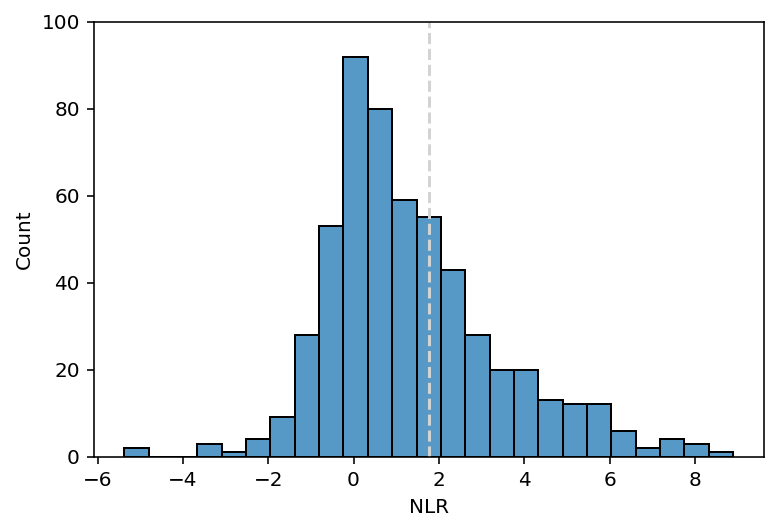

detected
False    0.638838
True     0.361162
Name: proportion, dtype: float64
detected
False    352
True     199
Name: count, dtype: int64


In [49]:
sns.histplot(data=normalized_df.query("retest_type == 'nY2H_APWT' and db_mut_id == 0"), x='NLR')

plt.vlines(x=1.7573820895430956, ymin=0, ymax=100, linestyles='--', color='lightgrey')
plt.ylim(0,100);
plt.show();

print(normalized_df.query("retest_type == 'nY2H_APWT' and db_mut_id == 0 and invalid == False").detected.value_counts(normalize=True))
print(normalized_df.query("retest_type == 'nY2H_APWT' and db_mut_id == 0 and invalid == False").detected.value_counts(normalize=False))

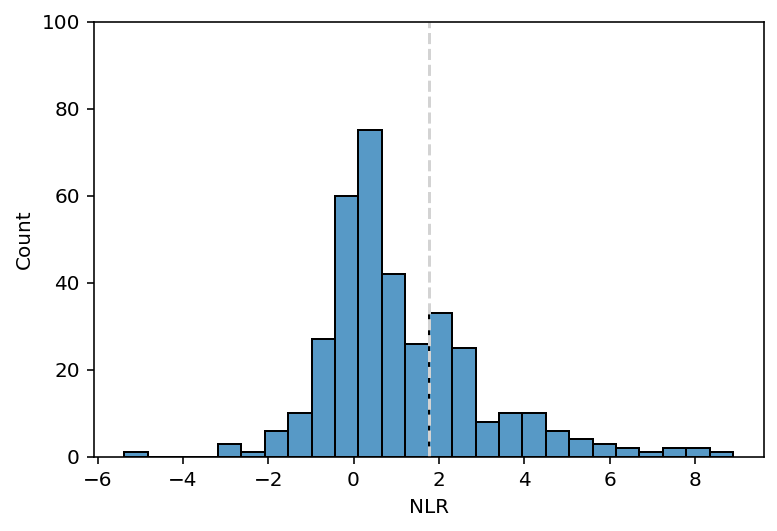

detected
False    0.70195
True     0.29805
Name: proportion, dtype: float64
detected
False    252
True     107
Name: count, dtype: int64


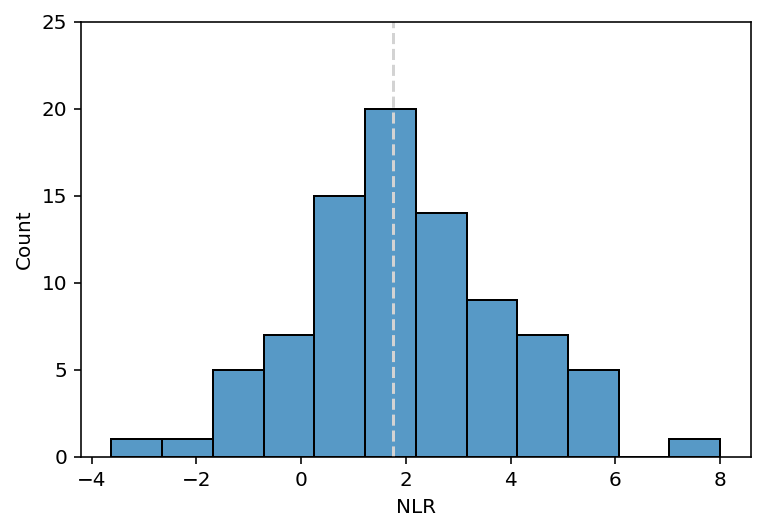

detected
True     0.541176
False    0.458824
Name: proportion, dtype: float64
detected
True     46
False    39
Name: count, dtype: int64


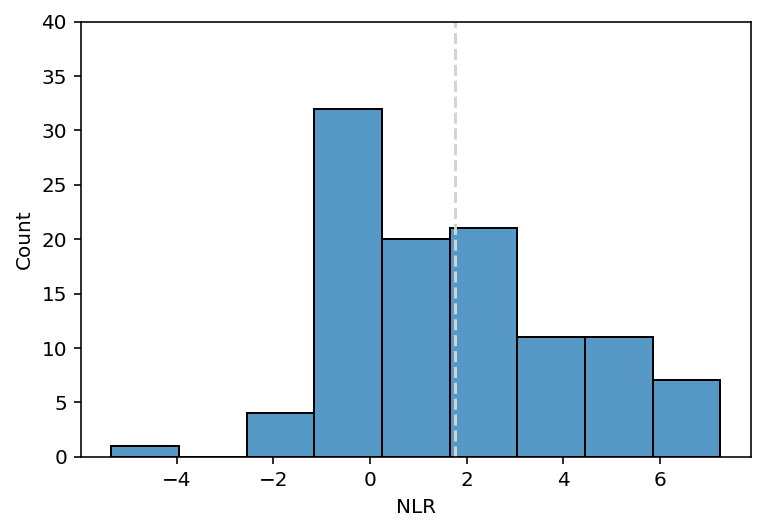

detected
False    0.570093
True     0.429907
Name: proportion, dtype: float64
detected
False    61
True     46
Name: count, dtype: int64


In [50]:
for assay_id, ymax in zip([1,2,6],[100,25,40]):
    sns.histplot(data=normalized_df.query(f"retest_type == 'nY2H_APWT' and db_mut_id == 0 and assay_id == {assay_id}"), x='NLR')

    plt.vlines(x=1.7573820895430956, ymin=0, ymax=100, linestyles='--', color='lightgrey')
    plt.ylim(0,ymax);
    plt.show();

    print(normalized_df.query(f"retest_type == 'nY2H_APWT' and db_mut_id == 0 and invalid == False and assay_id == {assay_id}").detected.value_counts(normalize=True))
    print(normalized_df.query(f"retest_type == 'nY2H_APWT' and db_mut_id == 0 and invalid == False and assay_id == {assay_id}").detected.value_counts(normalize=False))

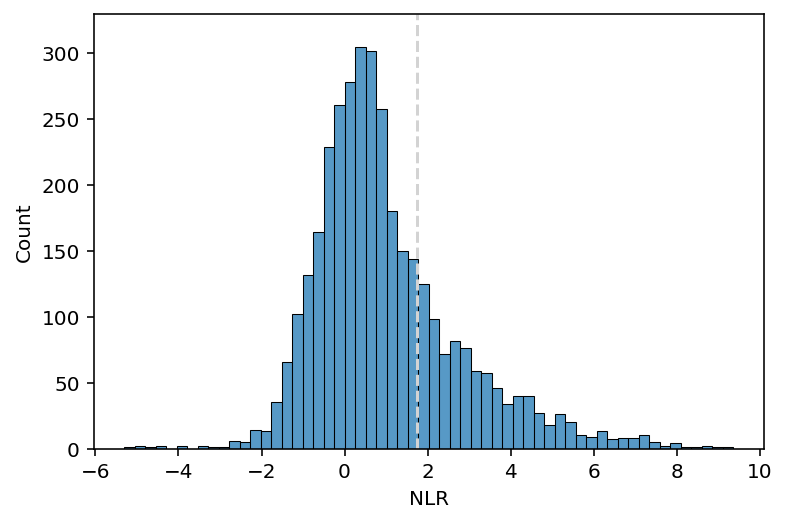

In [51]:
sns.histplot(data=normalized_df.query("retest_type == 'nY2H_APWT' and db_mut_id > 0"), x='NLR')

plt.vlines(x=1.7573820895430956, ymin=0, ymax=330, linestyles='--', color='lightgrey')
plt.ylim(0,330);

In [52]:
normalized_df.query("retest_type == 'nY2H_APWT' and db_mut_id == 0 and invalid == False").detected.value_counts(normalize=True)

detected
False    0.638838
True     0.361162
Name: proportion, dtype: float64

In [53]:
normalized_df.query("retest_type == 'nY2H_APWT' and db_mut_id == 0 and invalid == False").detected.value_counts(normalize=False)

detected
False    352
True     199
Name: count, dtype: int64

In [54]:
normalized_df.query("retest_type == 'nY2H_APWT' and db_mut_id > 0").detected.value_counts(normalize=True)

detected
False    0.771142
True     0.228858
Name: proportion, dtype: float64

In [55]:
retest_df.retest_type.value_counts()

retest_type
nY2H_APWT             5989
kd                     650
MAD2L1_MAD1L1_ctrl     156
LCP2_GRAP2_ctrl        156
secret_code            128
Name: count, dtype: int64

## Allele dataframe

In [57]:
#wt_nlr_d =  

allele_df = normalized_df.query("db_mut_id > 0").copy()

allele_df.head()

,db_orf_id,db_symbol,db_mut_id,ad_orf_id,ad_symbol,assay_id,retest_type,RLU,RLU_log10,empty_well,invalid,RLU_ctrl,NLR,detected,Kd
694,11805.0,SMAD3,2134.0,71704.0,SMURF2,1.0,nY2H_APWT,238037,5.376644,False,False,16380.0,3.861179,True,NaN
695,11805.0,SMAD3,2145.0,71704.0,SMURF2,1.0,nY2H_APWT,198593,5.297964,False,False,26273.0,2.918162,True,NaN
696,11805.0,SMAD3,2173.0,71704.0,SMURF2,1.0,nY2H_APWT,758081,5.879716,False,False,48924.0,3.953738,True,NaN
697,11805.0,SMAD3,2117.0,71704.0,SMURF2,1.0,nY2H_APWT,407918,5.610573,False,False,48497.0,3.072312,True,NaN
698,11805.0,SMAD3,203607.0,71704.0,SMURF2,1.0,nY2H_APWT,261063,5.416745,False,False,66868.0,1.965010,True,NaN


In [ ]:
normalized_df[(normalized_df.db_mut_id == 0)&(normalized_df.db_symbol == 'MLH1')]

,db_orf_id,db_symbol,db_mut_id,ad_orf_id,ad_symbol,assay_id,retest_type,RLU,RLU_log10,empty_well,invalid,RLU_ctrl,NLR,detected,Kd
846,2713.0,MLH1,0.0,71963.0,MBD3L1,6.0,nY2H_APWT,910558,5.959308,False,False,10253.0,6.472633,True,NaN
891,2713.0,MLH1,0.0,53964.0,NFIX,1.0,nY2H_APWT,51130,4.708676,False,False,19307.0,1.405046,False,NaN
940,2713.0,MLH1,0.0,1611.0,SPERT,1.0,nY2H_APWT,79089,4.898116,False,False,19307.0,2.034353,True,NaN
985,2713.0,MLH1,0.0,4761.0,AP2B1,1.0,nY2H_APWT,709492,5.850948,False,False,19307.0,5.199591,True,NaN
1078,2713.0,MLH1,0.0,14404.0,SPATA8,6.0,nY2H_APWT,1440112,6.158396,False,False,10253.0,7.133991,True,NaN
1128,2713.0,MLH1,0.0,15066.0,CXorf57,1.0,nY2H_APWT,15391,4.187267,False,False,19307.0,-0.327037,False,NaN
1172,2713.0,MLH1,0.0,2658.0,ZNF559-ZNF177,6.0,nY2H_APWT,32773,4.515516,False,False,10253.0,1.676462,False,NaN
1222,2713.0,MLH1,0.0,11671.0,FAN1,2.0,nY2H_APWT,9374,3.971925,False,False,19197.0,-1.034144,False,NaN
1267,2713.0,MLH1,0.0,6853.0,MBD4,2.0,nY2H_APWT,71406,4.853735,False,False,19197.0,1.895164,True,NaN
1316,2713.0,MLH1,0.0,4351.0,NME4,6.0,nY2H_APWT,50285,4.701438,False,False,10253.0,2.294082,True,NaN


In [ ]:
stop

NameError: name 'stop' is not defined

## QC analysis

In [ ]:
retest_df.retest_type.value_counts()

In [ ]:
plt.figure(figsize=(20,5))
sns.scatterplot(data=retest_df.query("(retest_type == 'MAD2L1_MAD1L1_ctrl' or retest_type == 'LCP2_GRAP2_ctrl') and (empty_well == False)"), 
                x='dest_pla_id', y='RLU_log10', 
                hue='retest_type'
               )


plt.show()

In [ ]:
plt.figure(figsize=(20,5))
sns.scatterplot(data=retest_df.query("retest_type == 'MAD2L1_MAD1L1_ctrl' or retest_type == 'LCP2_GRAP2_ctrl' or retest_type == 'secret_code'"), 
                x='dest_pla_id', y='RLU_log10', 
                hue='retest_type', alpha=0.7
               )

#plt.xlabel()
plt.show()